# Grape Sugar Content (°Brix) Prediction from NIR and Raman Spectroscopy

This notebook demonstrates a complete SpectraScope workflow for predicting
grape sugar content (°Brix) from near-infrared (NIR) and Raman spectra.

**Data source:** [Ebrahimi et al., Grape Chemical Composition](https://github.com/imeb/Grape-Chemical-Composition/tree/main)

**Workflow:**
1. Load and preprocess spectra (center, scale, wavelength clip)
2. Initialize SpectraScope and generate spectral features
3. Train Random Forest, Lasso, Fused Lasso, and LCEN models
4. Evaluate model performance and analyze selected features
5. Random-variable control experiment to assess feature importance thresholds
6. LCEN hyperparameter sensitivity analysis


In [38]:
import sys 
%load_ext autoreload
%autoreload 2

from spectrascope.SpectraScope import *
from spectrascope.Features import * 
from sklearn.linear_model import Ridge, Lasso, ElasticNet
import os
from sklearn.base import clone

from matplotlib import gridspec
plt.style.use('../ss.mplstyle')

#utils for plotting
PRETTY_LABELS_DICT = {
        'nir_pointwise_features':'NIR, Intensity', 'rm_pointwise_features':'Raman, Intensity',
        'nir_polynomial_featuresall': 'NIR, Polynomial', 
        'rm_polynomial_featuresall':'Raman, Polynomial',
        'nir_cdf':'NIR, CDF', 
        'rm_cdf':'Raman, CDF',
        'nir_pca':'NIR, PCA', 
        'rm_pca':'Raman, PCA',
        'nir_featureagg':'NIR, Clustering', 
        'rm_featureagg': 'Raman, Clustering',
        'rm_nir_pointwise_features':'NIR + Raman, Intensity', 
        'nir_rm_polynomial_featuresall':'NIR + Raman, Polynomial',
        'nir_cwt': 'NIR, CWT'
}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Load Data

Raw spectra and target values (°Brix) are stored in the test files directory.
Original data from Ebrahimi et al.: [Grape-Chemical-Composition](https://github.com/imeb/Grape-Chemical-Composition/tree/main)

In [39]:
XSF_br = np.load('../tests/test_files/grapes_example/XSF_br.npy')
XRF_br = np.load('../tests/test_files/grapes_example/XRF_br.npy')
br = np.load('../tests/test_files/grapes_example/br.npy')
nir_wls = np.load('../tests/test_files/grapes_example/nir_xaxis.npy')
raman_wls = np.load('../tests/test_files/grapes_example/rm_xaxis.npy')

### Visualize Raw Spectra

Plot one representative NIR and Raman spectrum to inspect signal quality.

Text(0.5, 0.98, 'Raw Data')

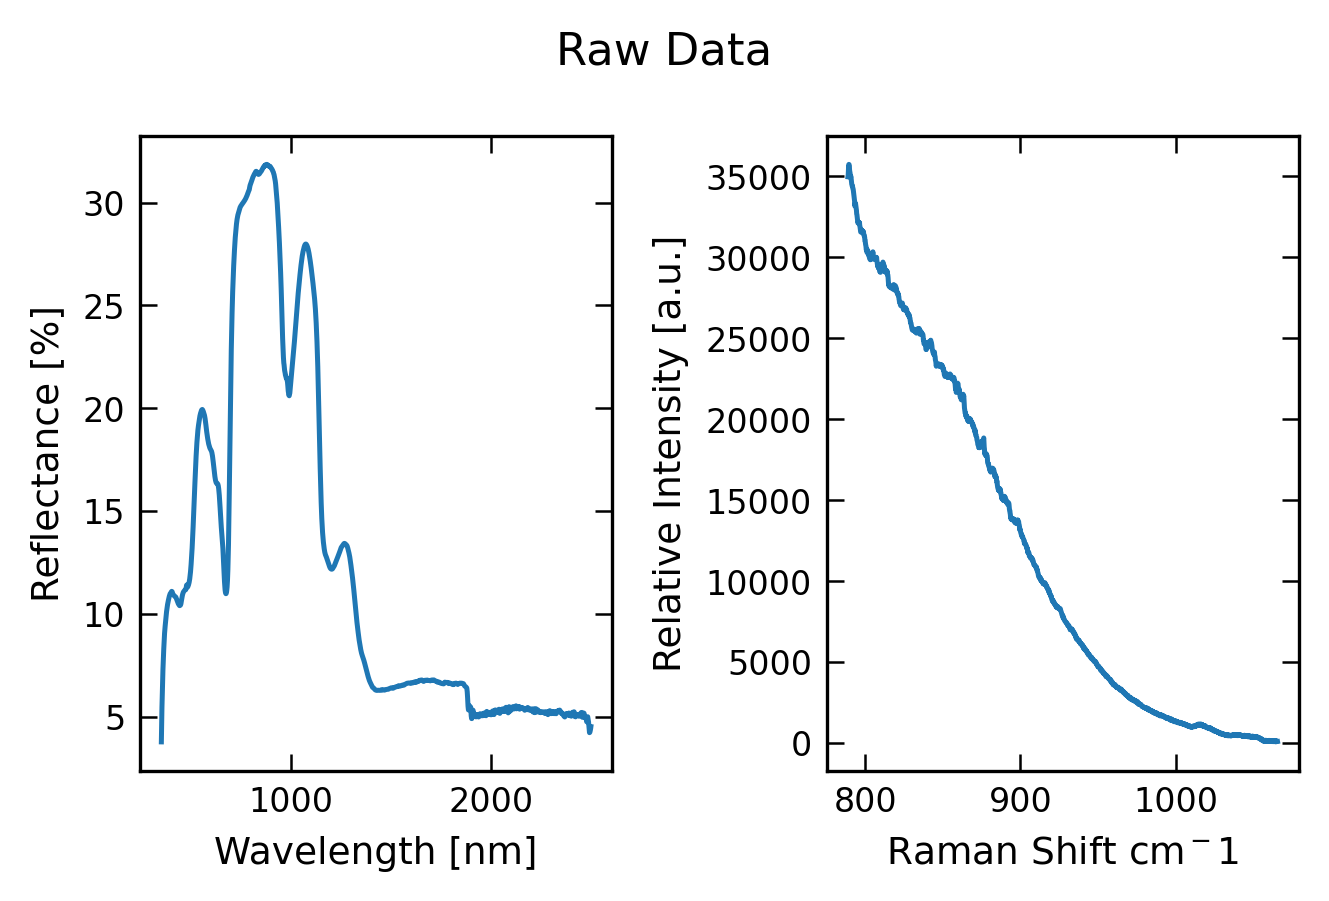

In [40]:
f, (ax1, ax2) = plt.subplots(1,2)
ax1.plot(nir_wls, XSF_br[0])
ax2.plot(raman_wls, XRF_br[0])

ax1.set_xlabel('Wavelength [nm]')
ax1.set_ylabel('Reflectance [%]')
ax2.set_xlabel(rf'Raman Shift $cm^{-1}$')
ax2.set_ylabel('Relative Intensity [a.u.]')
f.suptitle('Raw Data')


### Preprocess: Center and Scale

Each spectrum is mean-centered and then standardized (`StandardScaler`),
following the preprocessing in Ebrahimi et al.
The NIR spectra are additionally clipped to the 400–1300 nm range.

In [41]:
# Centering the data 

XSF_br_centered = np.zeros(XSF_br.shape)
for i,arr in enumerate(XSF_br): 
    arr = arr - np.mean(arr)
    XSF_br_centered[i] = arr

XRF_br_centered = np.zeros(XRF_br.shape)
for i,arr in enumerate(XRF_br): 
    arr = arr - np.mean(arr)
    XRF_br_centered[i] = arr


from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

XSF_br_centered_scaled = scaler.fit_transform(XSF_br_centered)
XRF_br_centered_scaled = scaler.fit_transform(XRF_br_centered)

# only look at 400-1300nm 
selected_wls = np.argwhere((nir_wls > 400) &  (nir_wls < 1300))[:,0]
XSF_br_centered_scaled  = XSF_br_centered_scaled[:,selected_wls]

### Initialize SpectraScope

Create a `SpectraScope` object with the preprocessed NIR and Raman arrays
and register the corresponding wavelength axes.

In [42]:
XF = [XSF_br, XRF_br]# not using the centered and scaled data
XF = [XSF_br_centered_scaled, XRF_br_centered_scaled] # using centered and scaled data

ss_f = SpectraScope(XF, br, specnames=['nir', 'rm'], yname='br', random_seed=10)
ss_f.add_x_axis('rm', raman_wls)
ss_f.add_x_axis('nir', nir_wls[selected_wls])

saving to /examples/models, change save_path kwarg if youd like to change


### Generate Spectral Features

For each modality (NIR and Raman) generate all feature types:
pointwise intensities, CDF, clustering aggregation, polynomial fits,
PCA projections, CWT coefficients, and FFT features (NIR only).
Then combine the two pointwise feature matrices into a joint representation.

In [43]:
ss_f.add_spectral_feature('rm', 'pointwise_features', xrange=ss_f.rm_xaxis)
ss_f.add_spectral_feature('rm', 'polynomial_featuresall')
ss_f.add_spectral_feature('rm', 'featureagg', n_clusters=15)
ss_f.add_spectral_feature('rm', 'pca', n_components=15)
ss_f.add_spectral_feature('rm', 'cdf')
ss_f.add_spectral_feature('rm', 'cwt')

ss_f.add_spectral_feature('nir', 'pointwise_features', xrange=ss_f.nir_xaxis)
ss_f.add_spectral_feature('nir', 'polynomial_featuresall')
ss_f.add_spectral_feature('nir', 'featureagg', n_clusters=15)
ss_f.add_spectral_feature('nir', 'pca', n_components=15)
ss_f.add_spectral_feature('nir', 'cdf')
ss_f.add_spectral_feature('nir', 'cwt')
ss_f.add_spectral_feature('nir', 'fft_features', xrange=ss_f.nir_xaxis)

## combine modalities 
ss_f.combine_feature('rm_pointwise_features', 'nir_pointwise_features')

### Set Up Hyperparameter Grids for Cross-Validation

Define `kwargs` dicts for each model type:
Random Forest, LCEN, Lasso, Linear Regression, and Fused Lasso.

In [44]:
from sklearn.metrics import root_mean_squared_error
from spectrascope.FusedLasso import FusedLasso
from sklearn.linear_model import LinearRegression
RF_kwargs = {'estimator':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[50, 100, 200], 
                                        'criterion':['squared_error'],
                                        'max_depth': [50, None]},
                'refit':True,
                'scale_X':False, # Make sure False if input data is scaled and centered
                'metric':root_mean_squared_error, 
                'scoring':'neg_mean_squared_error'}

lcen_kwargs = {'l1_ratio':[0.001, 0.01, 0.1,0.3, 0.5, 0.75,1], #was previously just 1
               'K_fold':5, 
               'cv_method':'Kfold', 
               'alpha':5, #change from 5 to 15
               'degree':[1],
               'trans_type':'poly', 
               'LCEN_cutoff':5e-5, 
               'LCEN_interaction':False, 
               'scale_X':True, # Make sure False if input data is scaled and centered
               'scale_y':True, #changed from True 
               'metric':root_mean_squared_error}


Lasso_kwargs = {'estimator':Lasso(), 
            'param_grid':{'alpha':[0.1,0.3,0.5,0.9],
            'fit_intercept':[True]},
            'refit':True, 
            'metric':root_mean_squared_error  
            }

Linear_kwargs = {'estimator':LinearRegression()}

fused_kwargs = {'estimator':FusedLasso(),
    'param_grid':{'alpha':[0.3,0.5,0.9],
                            'fit_intercept':[True]
                    },
                'refit':True,
                'scoring':'neg_mean_squared_error',
                'metric':root_mean_squared_error
}

### Train Scikit-Learn Models

Train Random Forest, Linear Regression, and Lasso on every
(modality, feature-type) combination, plus the combined NIR + Raman feature.

In [45]:
feats = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']#, 'pointwise_features_trans',] #uncomment for nonlinear transformations
for spec in ss_f.specnames:
    for feat in feats: 
        attr_name = f'{spec}_{feat}'
        ss_f.do_sk(attr_name, 'br', 0.25, use_pipeline=True, **RF_kwargs)
        ss_f.do_sk(attr_name, 'br', 0.25, use_pipeline=False, **Linear_kwargs)
        ss_f.do_sk(attr_name, 'br', 0.25, use_pipeline=True, **Lasso_kwargs)
ss_f.do_sk('rm_nir_pointwise_features', 'br', 0.25, use_pipeline=True, **RF_kwargs)
ss_f.do_sk('rm_nir_pointwise_features', 'br', 0.25, use_pipeline=False, **Linear_kwargs)
ss_f.do_sk('rm_nir_pointwise_features', 'br', 0.25, use_pipeline=True, **Lasso_kwargs)

/Users/amalyajohnson/miniconda3/envs/spec/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.220e-02, tolerance: 5.854e-02
  model = cd_fast.enet_coordinate_descent(
/Users/amalyajohnson/miniconda3/envs/spec/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.755e-02, tolerance: 5.639e-02
  model = cd_fast.enet_coordinate_descent(
/Users/amalyajohnson/miniconda3/envs/spec/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of 

already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted


/Users/amalyajohnson/miniconda3/envs/spec/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.147e-02, tolerance: 5.639e-02
  model = cd_fast.enet_coordinate_descent(
/Users/amalyajohnson/miniconda3/envs/spec/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.820e-02, tolerance: 6.408e-02
  model = cd_fast.enet_coordinate_descent(
/Users/amalyajohnson/miniconda3/envs/spec/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of 

### Train Fused Lasso Models

Train the Fused Lasso (contiguous-coefficient regularization) on each
feature set. Falls back gracefully if the solver fails to converge.

In [46]:
for spec in ss_f.specnames:
    for feat in feats: 
        attr_name = f'{spec}_{feat}'
        try: 
            ss_f.do_sk(attr_name, 'br', 0.25, use_pipeline=False, **fused_kwargs)
        except RuntimeError: 
            print(spec, feat)
            continue

ss_f.do_sk('nir_pointwise_features', 'br', 0.25, use_pipeline=False, estimator=FusedLasso(alpha=0.5), metric=mean_squared_error)

nir pointwise_features
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted


### Train LCEN Models

Train LCEN (L1-penalized Cascade ElasticNet) on every feature set.
LCEN performs both feature transformation and automatic feature selection.

In [47]:
feats_lcen = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']

for spec in ss_f.specnames:
    for feat in feats_lcen: 
        attr_name = f'{spec}_{feat}'
        ss_f.do_LCEN(attr_name, 'br', 0.25, **lcen_kwargs)

ss_f.do_LCEN('rm_nir_pointwise_features', 'br', 0.25, **lcen_kwargs)

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.6418 | Mean relative error = 0.0305
Test set : RMSE = 0.9331 | Mean relative error = 0.0437
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 2.3157 | Mean relative error = 0.1023
Test set : RMSE = 2.2532 | Mean relative error = 0.0931
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its resul

### Random Forest — CV Split Results

Plot per-fold % RMSE for each hyperparameter combination across all
feature sets. Also collects a summary table for the supplementary.

rm_cwt
nir_cwt
nir_fft_features
rm_nir_pointwise_features


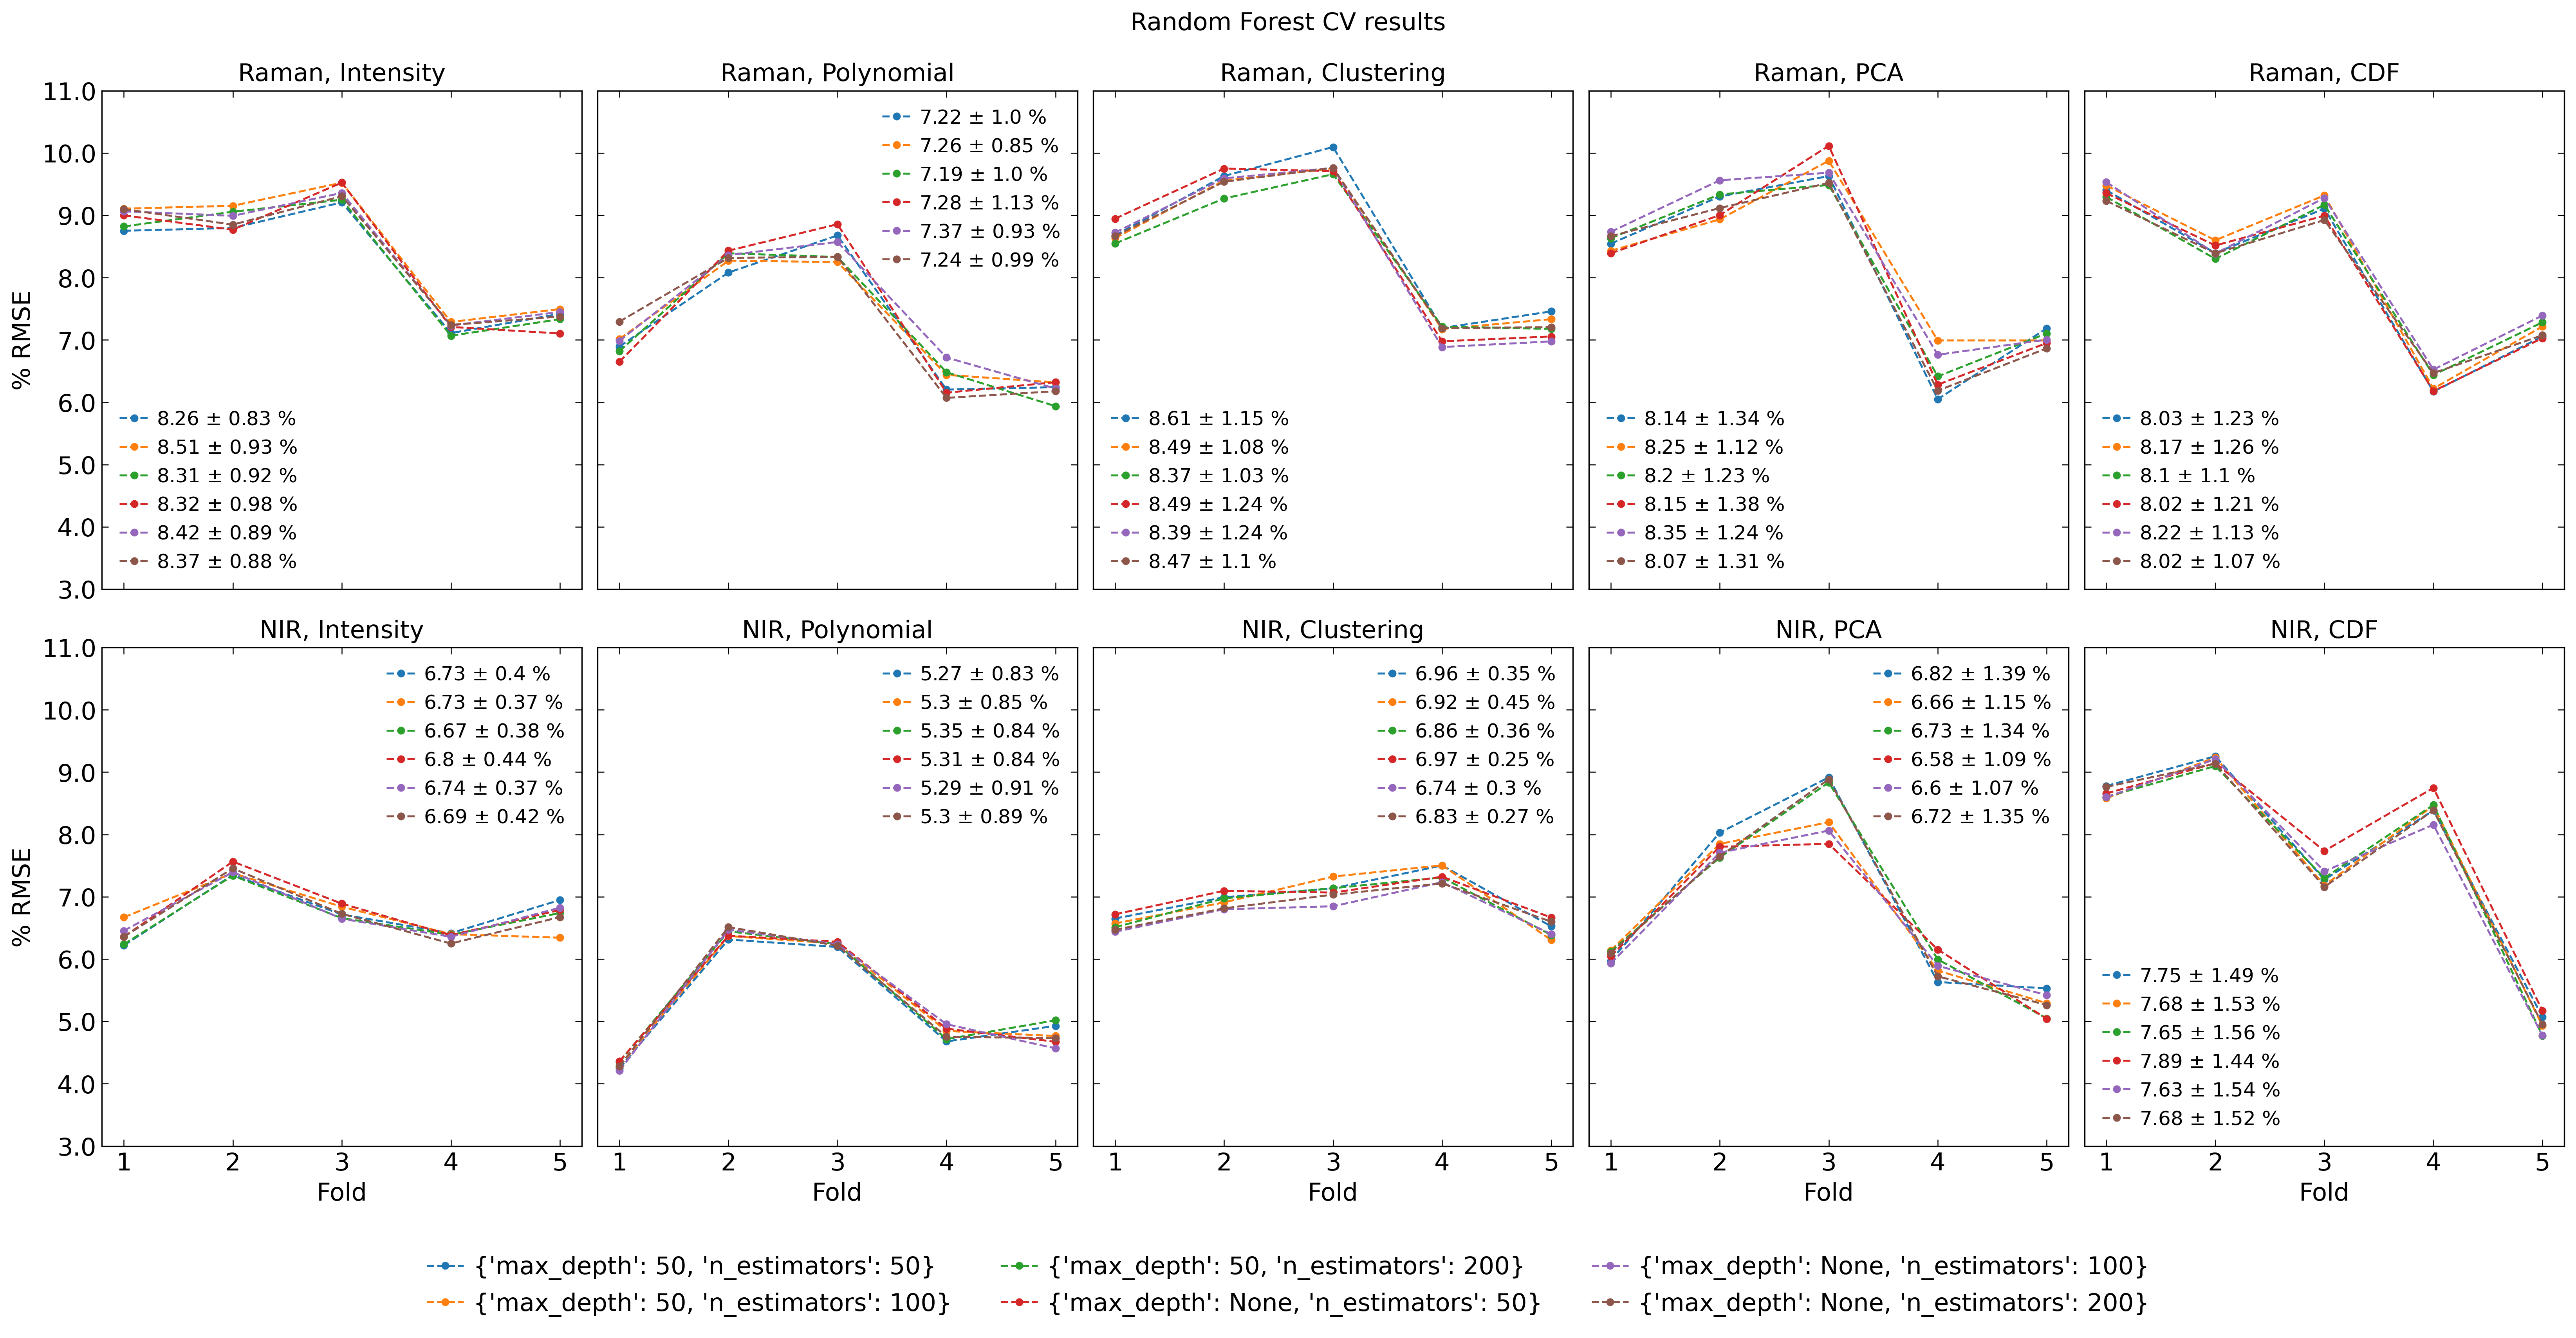

In [48]:
f, axs = plt.subplots(2,5, figsize=(22,10), sharex=True, sharey=True)
axs = axs.ravel()
i = 0 
rf_cv_table = []
for _, attr_name in enumerate(ss_f.generated_features): 
    try: 
        gs = getattr(ss_f, f'{attr_name}_br_RandomForestRegressor')['P'][0]
        cv_results = gs.cv_results_
        cv_results = pd.DataFrame(cv_results)
        if i == 0: 
            legend_handles = []
        for row in cv_results.iterrows():
            mean, std = row[1]['mean_test_score'], row[1]['std_test_score']
            scores = row[1][['split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score']]
            params = row[1]['params']
            params = {'max_depth': params['max_depth'], 'n_estimators': params['n_estimators']}
            if i == 0: 
                legend_handles.append(params)
            prmse = np.sqrt(np.abs(scores.astype(float))) * 100 / np.max(ss_f.br)
            axs[i].plot(np.arange(5), prmse, label=f'{np.round(np.mean(prmse),2)} $\pm$ {np.round(np.std(prmse),2)} %', marker='o', linestyle='--')
            axs[i].legend(fontsize=12)
            axs[i].set_title(PRETTY_LABELS_DICT[attr_name], size=15)
        
        if not cv_results.empty:
            # Find best and worst by mean_test_score
            idx_best = cv_results['mean_test_score'].idxmax()
            idx_worst = cv_results['mean_test_score'].idxmin()
            params_best = cv_results.loc[idx_best, 'params']
            params_worst = cv_results.loc[idx_worst, 'params']
            scores_best = cv_results.loc[idx_best][['split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score']].astype(float)
            scores_worst = cv_results.loc[idx_worst][['split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score']].astype(float)
            scores_best = np.sqrt(np.abs(scores_best)) * 100 / np.max(ss_f.br)
            scores_worst = np.sqrt(np.abs(scores_worst)) * 100 / np.max(ss_f.br)
            mean_best = np.mean(scores_best)
            mean_worst = np.mean(scores_worst)
            std_best = np.std(scores_best)
            std_worst = np.std(scores_worst)
            def param_str(params):
                wanted = ['max_depth', 'n_estimators']  # change keys as appropriate
                return ', '.join([f"{k}={params[k]}" for k in wanted if k in params])
            best_str = param_str(params_best).replace('max_depth=', '').replace('n_estimators=', '')
            best_str = '(' + best_str + ')'
            worst_str = param_str(params_worst).replace('max_depth=', '').replace('n_estimators=', '')
            worst_str = '(' + worst_str + ')'
            rf_cv_table.append({
                'Feature': PRETTY_LABELS_DICT[attr_name] if attr_name in PRETTY_LABELS_DICT else attr_name,
                'Best (mean ± std)': f"{mean_best:.2f} ± {std_best:.2f}",
                'Best hyperparams (depth, N)': best_str,
                'Worst (mean ± std)': f"{mean_worst:.2f} ± {std_worst:.2f}",
                'Worst hyperparams (depth, N)': worst_str,
            })
        i +=1
    except: 
        print(attr_name)
        continue

handles, labels = axs[-1].get_legend_handles_labels()
# axs[-1].axis("off")
f.legend(handles, legend_handles, loc='lower center', fontsize=15, bbox_to_anchor=(0.5, -0.1), ncols=3, frameon=False)

axs[0].set_ylabel('% RMSE', fontsize=15)
axs[5].set_ylabel('% RMSE', fontsize=15)

axs[5].set_xlabel('Fold', fontsize=15)
axs[6].set_xlabel('Fold', fontsize=15)
axs[7].set_xlabel('Fold', fontsize=15)
axs[8].set_xlabel('Fold', fontsize=15)
axs[9].set_xlabel('Fold', fontsize=15)

for ax in axs: 
    ax.set_xticks([0,1,2,3,4], labels=[1,2,3,4,5], fontsize=15)
    ax.set_yticks(ax.get_yticks(), labels=np.round(ax.get_yticks(),2), fontsize=15)

plt.tight_layout()
f.suptitle('Random Forest CV results', fontsize=15, y=1.03)
plt.savefig('Figures/Grapes_RF_CV.pdf')

#### Hyperparameter Summary Table (Supplementary)

Print a LaTeX table of best/worst RF hyperparameter configurations.

In [49]:
df = pd.DataFrame(rf_cv_table)
print(df.to_latex(
        index='Feature',
        caption='Table',
        label='Label',
        escape=False  # allows math symbols
    ))

\begin{table}
\caption{Table}
\label{Label}
\begin{tabular}{llllll}
\toprule
 & Feature & Best (mean ± std) & Best hyperparams (depth, N) & Worst (mean ± std) & Worst hyperparams (depth, N) \\
\midrule
0 & Raman, Intensity & 8.26 ± 0.83 & (50, 50) & 8.51 ± 0.93 & (50, 100) \\
1 & Raman, Polynomial & 7.19 ± 1.00 & (50, 200) & 7.37 ± 0.93 & (None, 100) \\
2 & Raman, Clustering & 8.37 ± 1.03 & (50, 200) & 8.61 ± 1.15 & (50, 50) \\
3 & Raman, PCA & 8.07 ± 1.31 & (None, 200) & 8.35 ± 1.24 & (None, 100) \\
4 & Raman, CDF & 8.02 ± 1.07 & (None, 200) & 8.22 ± 1.13 & (None, 100) \\
5 & NIR, Intensity & 6.67 ± 0.38 & (50, 200) & 6.80 ± 0.44 & (None, 50) \\
6 & NIR, Polynomial & 5.27 ± 0.83 & (50, 50) & 5.35 ± 0.84 & (50, 200) \\
7 & NIR, Clustering & 6.74 ± 0.30 & (None, 100) & 6.97 ± 0.25 & (None, 50) \\
8 & NIR, PCA & 6.58 ± 1.09 & (None, 50) & 6.82 ± 1.39 & (50, 50) \\
9 & NIR, CDF & 7.63 ± 1.54 & (None, 100) & 7.89 ± 1.44 & (None, 50) \\
\bottomrule
\end{tabular}
\end{table}



In [50]:
# CV fits on the training set 

from sklearn.model_selection import KFold

kf = KFold(n_splits=5, random_state=12, shuffle=True)
feats = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']#, 'pointwise_features_trans',] #uncomment for nonlinear transformations
cv_results = {}
for spec in ss_f.specnames:
    for feat in feats: 
        X = getattr(ss_f, f'{spec}_{feat}')
        y = ss_f.br
        for i, (train_index, test_index) in enumerate(kf.split(X)):
            X_train, X_test = X[train_index], X[test_index]
            y_train, y_test = y[train_index], y[test_index]
            P = getattr(ss_f, f'{spec}_{feat}_br_RandomForestRegressor')['P'][0]
            # P = clone(P)
            # P.fit(X_train, y_train)
            ypred = P.predict(X_test)
            score = root_mean_squared_error(y_test, ypred)
            if f'{spec}_{feat}' not in cv_results:  
                cv_results[f'{spec}_{feat}'] = []
            cv_results[f'{spec}_{feat}'].append(score)

In [51]:
X = ss_f.rm_nir_pointwise_features
y = ss_f.br
for i, (train_index, test_index) in enumerate(kf.split(X)):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    P = getattr(ss_f, f'rm_nir_pointwise_features_br_RandomForestRegressor')['P'][0]
    # P = clone(P)
    # P.fit(X_train, y_train)
    ypred = P.predict(X_test)
    score = root_mean_squared_error(y_test, ypred)
    if 'rm_nir_pointwise_features' not in cv_results:  
        cv_results['rm_nir_pointwise_features'] = []
    cv_results['rm_nir_pointwise_features'].append(score)

### LCEN — CV Split Results

Evaluate the trained LCEN models on each cross-validation fold
using the same `KFold` splits as the RF evaluation above.

In [52]:
from spectrascope.utils import predict_LCEN

feats_lcen = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']
cv_results_lcen = {}
for spec in ss_f.specnames:
    for feat in feats_lcen: 
        attr_name = f'{spec}_{feat}'
        X = getattr(ss_f, attr_name)
        y = ss_f.br
        for i, (train_index, test_index) in enumerate(kf.split(X)):
            X_train, X_test = X[train_index], X[test_index]
            y_train, y_test = y[train_index], y[test_index]
            # Get LCEN model 
            # model = getattr(ss_f, f'{attr_name}_br_LCEN')['final_model']
            # Fit to CV split 
            try: 
                # model = clone(model)
                # model.fit(X_train, y_train)
                ypred = predict_LCEN(getattr(ss_f, f'{attr_name}_br_LCEN'), X_test)
                score = root_mean_squared_error(y_test, ypred)
                # print(attr_name, score)
                if attr_name not in cv_results_lcen:  
                    cv_results_lcen[attr_name] = []
                cv_results_lcen[attr_name].append(score)
            except: 
                print(f'{attr_name} failed')
                continue

X = ss_f.rm_nir_pointwise_features
y = ss_f.br
# scaler = StandardScaler()
# X = scaler.fit_transform(X)
for i, (train_index, test_index) in enumerate(kf.split(X)):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    # model = getattr(ss_f, f'{attr_name}_br_LCEN')['final_model']
    # final_params = getattr(ss_f, f'{attr_name}_br_LCEN')['final_params']
    # # model = clone(model)
    # # model.fit(X_train, y_train)
    ypred = predict_LCEN(getattr(ss_f, f'rm_nir_pointwise_features_br_LCEN'), X_test)
    score = root_mean_squared_error(y_test, ypred)
    if 'rm_nir_pointwise_features' not in cv_results_lcen:  
        cv_results_lcen['rm_nir_pointwise_features'] = []
    cv_results_lcen['rm_nir_pointwise_features'].append(score)

### Utility Functions and Shared Setup

`plot_spectral_features_matplotlib` overlays polynomial-fit icons
on raw spectra to illustrate which regions LCEN selected.
`results_df` collects all best-fit scores for the heatmap visualizations.

In [53]:
import copy  
from PIL import Image
from spectrascope.SSPlotting import PlotModel as pm 
from spectrascope.SSPlotting import PlotSpectralFeatures as psf

results_df = copy.copy(pd.DataFrame(ss_f.best_fits).T)
labels = [
    'NIR, Intensity',
    'NIR, CDF',
    'NIR, Clustering',
    'NIR, Polynomial',
    'NIR, PCA',
    'Raman, Intensity',
    'Raman, CDF',
    'Raman, Clustering',
    'Raman, Polynomial',
    'Raman, PCA',
    'Raman & NIR, Intensity'
]

to_plot = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']
to_plot_nicenames = {'pointwise_features':'Interpolated Data', 
                     'cdf':'CDF', 
                     'featureagg':'Clustering', 
                     'polynomial_featuresall':'Polynomial Fits', 
                     'pca':'PCA'}

ytrue = ss_f.br_test

from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from spectrascope.Features import SpectralFeatures
import os

def plot_spectral_features_matplotlib(xaxis, raw, selected_features, ax=None,zoom=0.1,
                                      plot_raw=True, print_centers=False):
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    
    # Plot the raw spectrum
    if plot_raw:
        ax.plot(xaxis, raw, color='black', lw=1)

    # Generate binned features
    temp = SpectralFeatures(xaxis, raw)
    for bins in [4, 5, 10, 20]:
        temp.generate_bins(bins)

    # Feature ID config
    feature_config = [
        (0, 16,  'bin_indices_4',  'const', 4),
        (16, 36, 'bin_indices_5',  'line',  5),
        (36, 76, 'bin_indices_10', 'par',   10),
        (76, 156, 'bin_indices_20', 'cubic', 20),
    ]

    def find_nearest(array, value):
        return np.abs(array - value).argmin()
    centers_used = []
    for selected_id in selected_features:
        for id_min, id_max, bin_label, poly_label, num_bins in feature_config:
            if id_min <= selected_id < id_max:
                search_bins = np.linspace(id_min, id_max, num_bins)
                located_bin = np.argwhere(selected_id < search_bins)[0][0]
                bin_mask = getattr(temp, bin_label) == located_bin
                center = np.median(xaxis[bin_mask])
                height_id = find_nearest(xaxis, center)
                height = raw[height_id]

                # Load image
                img_path = f"../app/static/{poly_label}.png"
                if not os.path.exists(img_path):
                    print(f"Warning: {img_path} not found.")
                    continue
                im = Image.open(img_path)

                # Convert image to matplotlib offsetbox
                imagebox = OffsetImage(im, zoom=zoom)
                if center in centers_used: 
                    add_to_height = 1  # slight offset to avoid overlap
                else: 
                    add_to_height = 0 
                ab = AnnotationBbox(imagebox, (center, height + add_to_height), frameon=False)
                centers_used.append(center)
                if print_centers: 
                    print(center, selected_id)

                ax.add_artist(ab)
                break  # stop after first matching range

    return ax


### Quick Performance Overview

% RMSE = $\frac{\sqrt{\text{MSE}}}{y_{\text{max}}} \cdot 100$

Heatmaps compare all models across all feature representations.

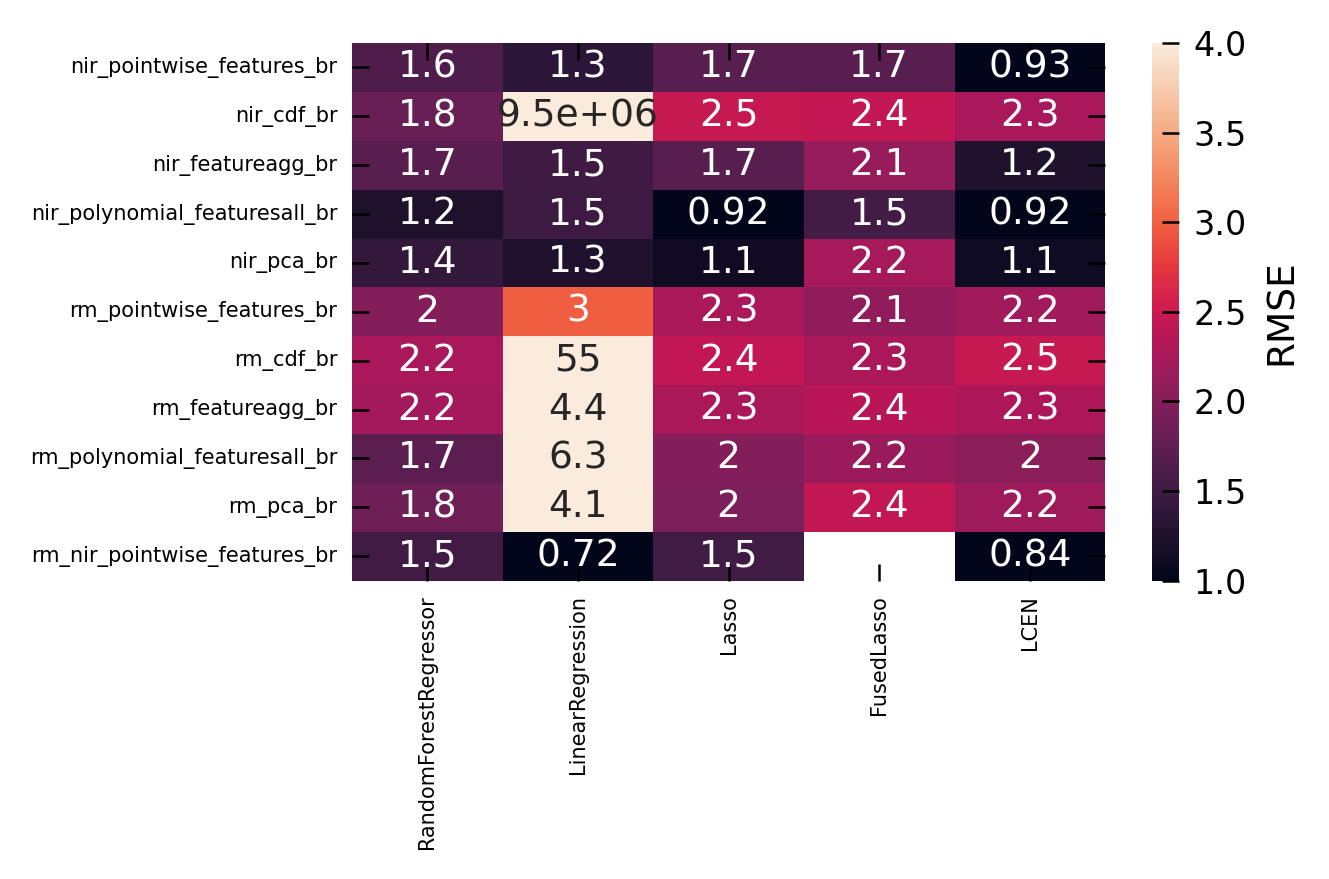

In [54]:
import seaborn as sns

# sns.heatmap((results_df.T) / np.max(ss_f.br) * 100, annot=True, cbar_kws={'label': '% RMSE'})
sns.heatmap((results_df.T) , annot=True, cbar_kws={'label': 'RMSE'}, vmin=1, vmax=4)
plt.xticks(size=5);
plt.yticks(size=5);

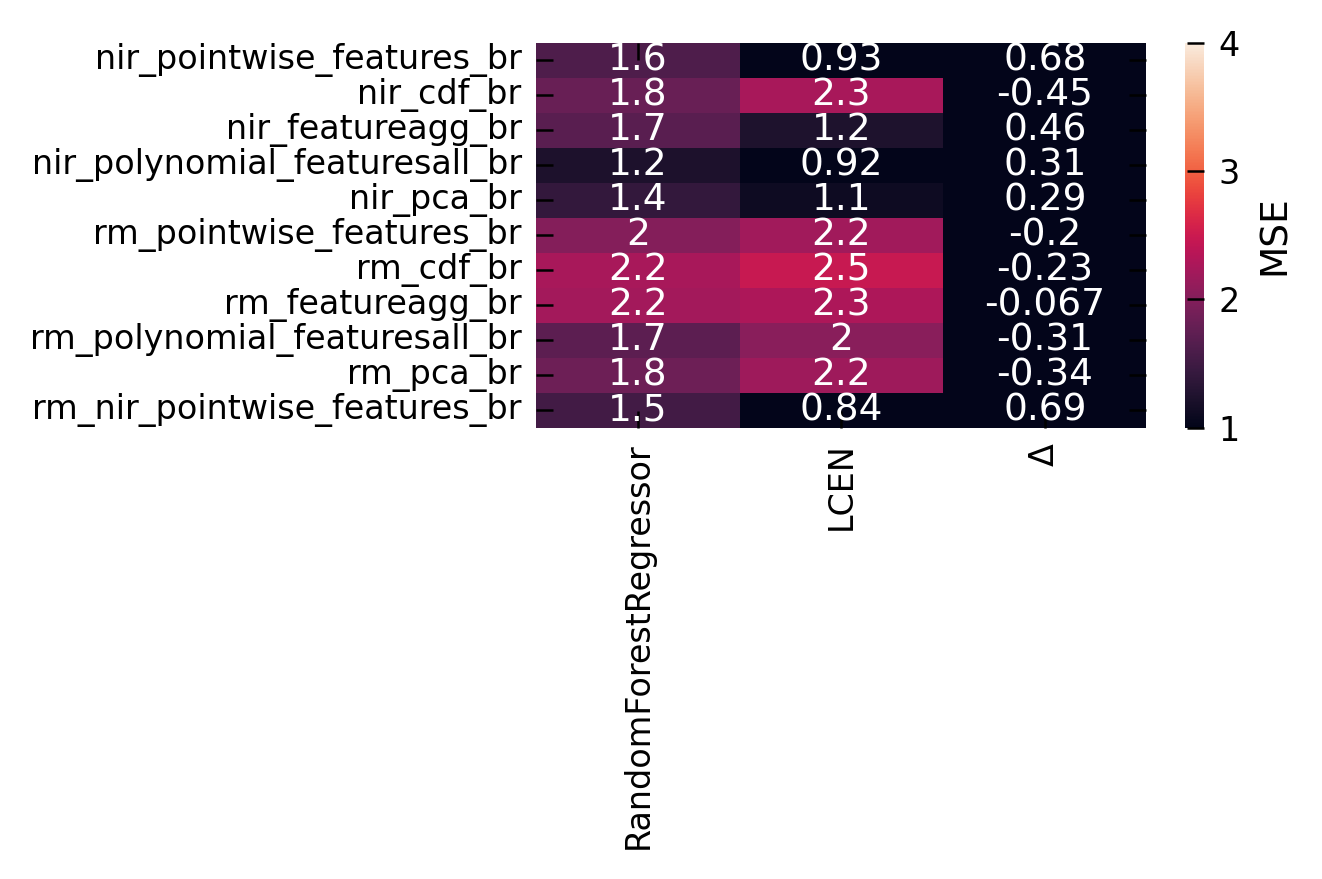

In [55]:
temp = (results_df.T)[['RandomForestRegressor', 'LCEN']] 
temp[r'$\Delta$'] = results_df.T['RandomForestRegressor'] - results_df.T['LCEN']
sns.heatmap(temp , annot=True, cbar_kws={'label': 'MSE'}, vmin=1, vmax=4)
plt.xticks(size=8,rotation=90);
plt.yticks(size=8);

### Correlation Analysis

Plot 5-fold CV % RMSE for RF and LCEN grouped by modality,
then compute Pearson correlation and mutual information between
the generated features and the °Brix target.

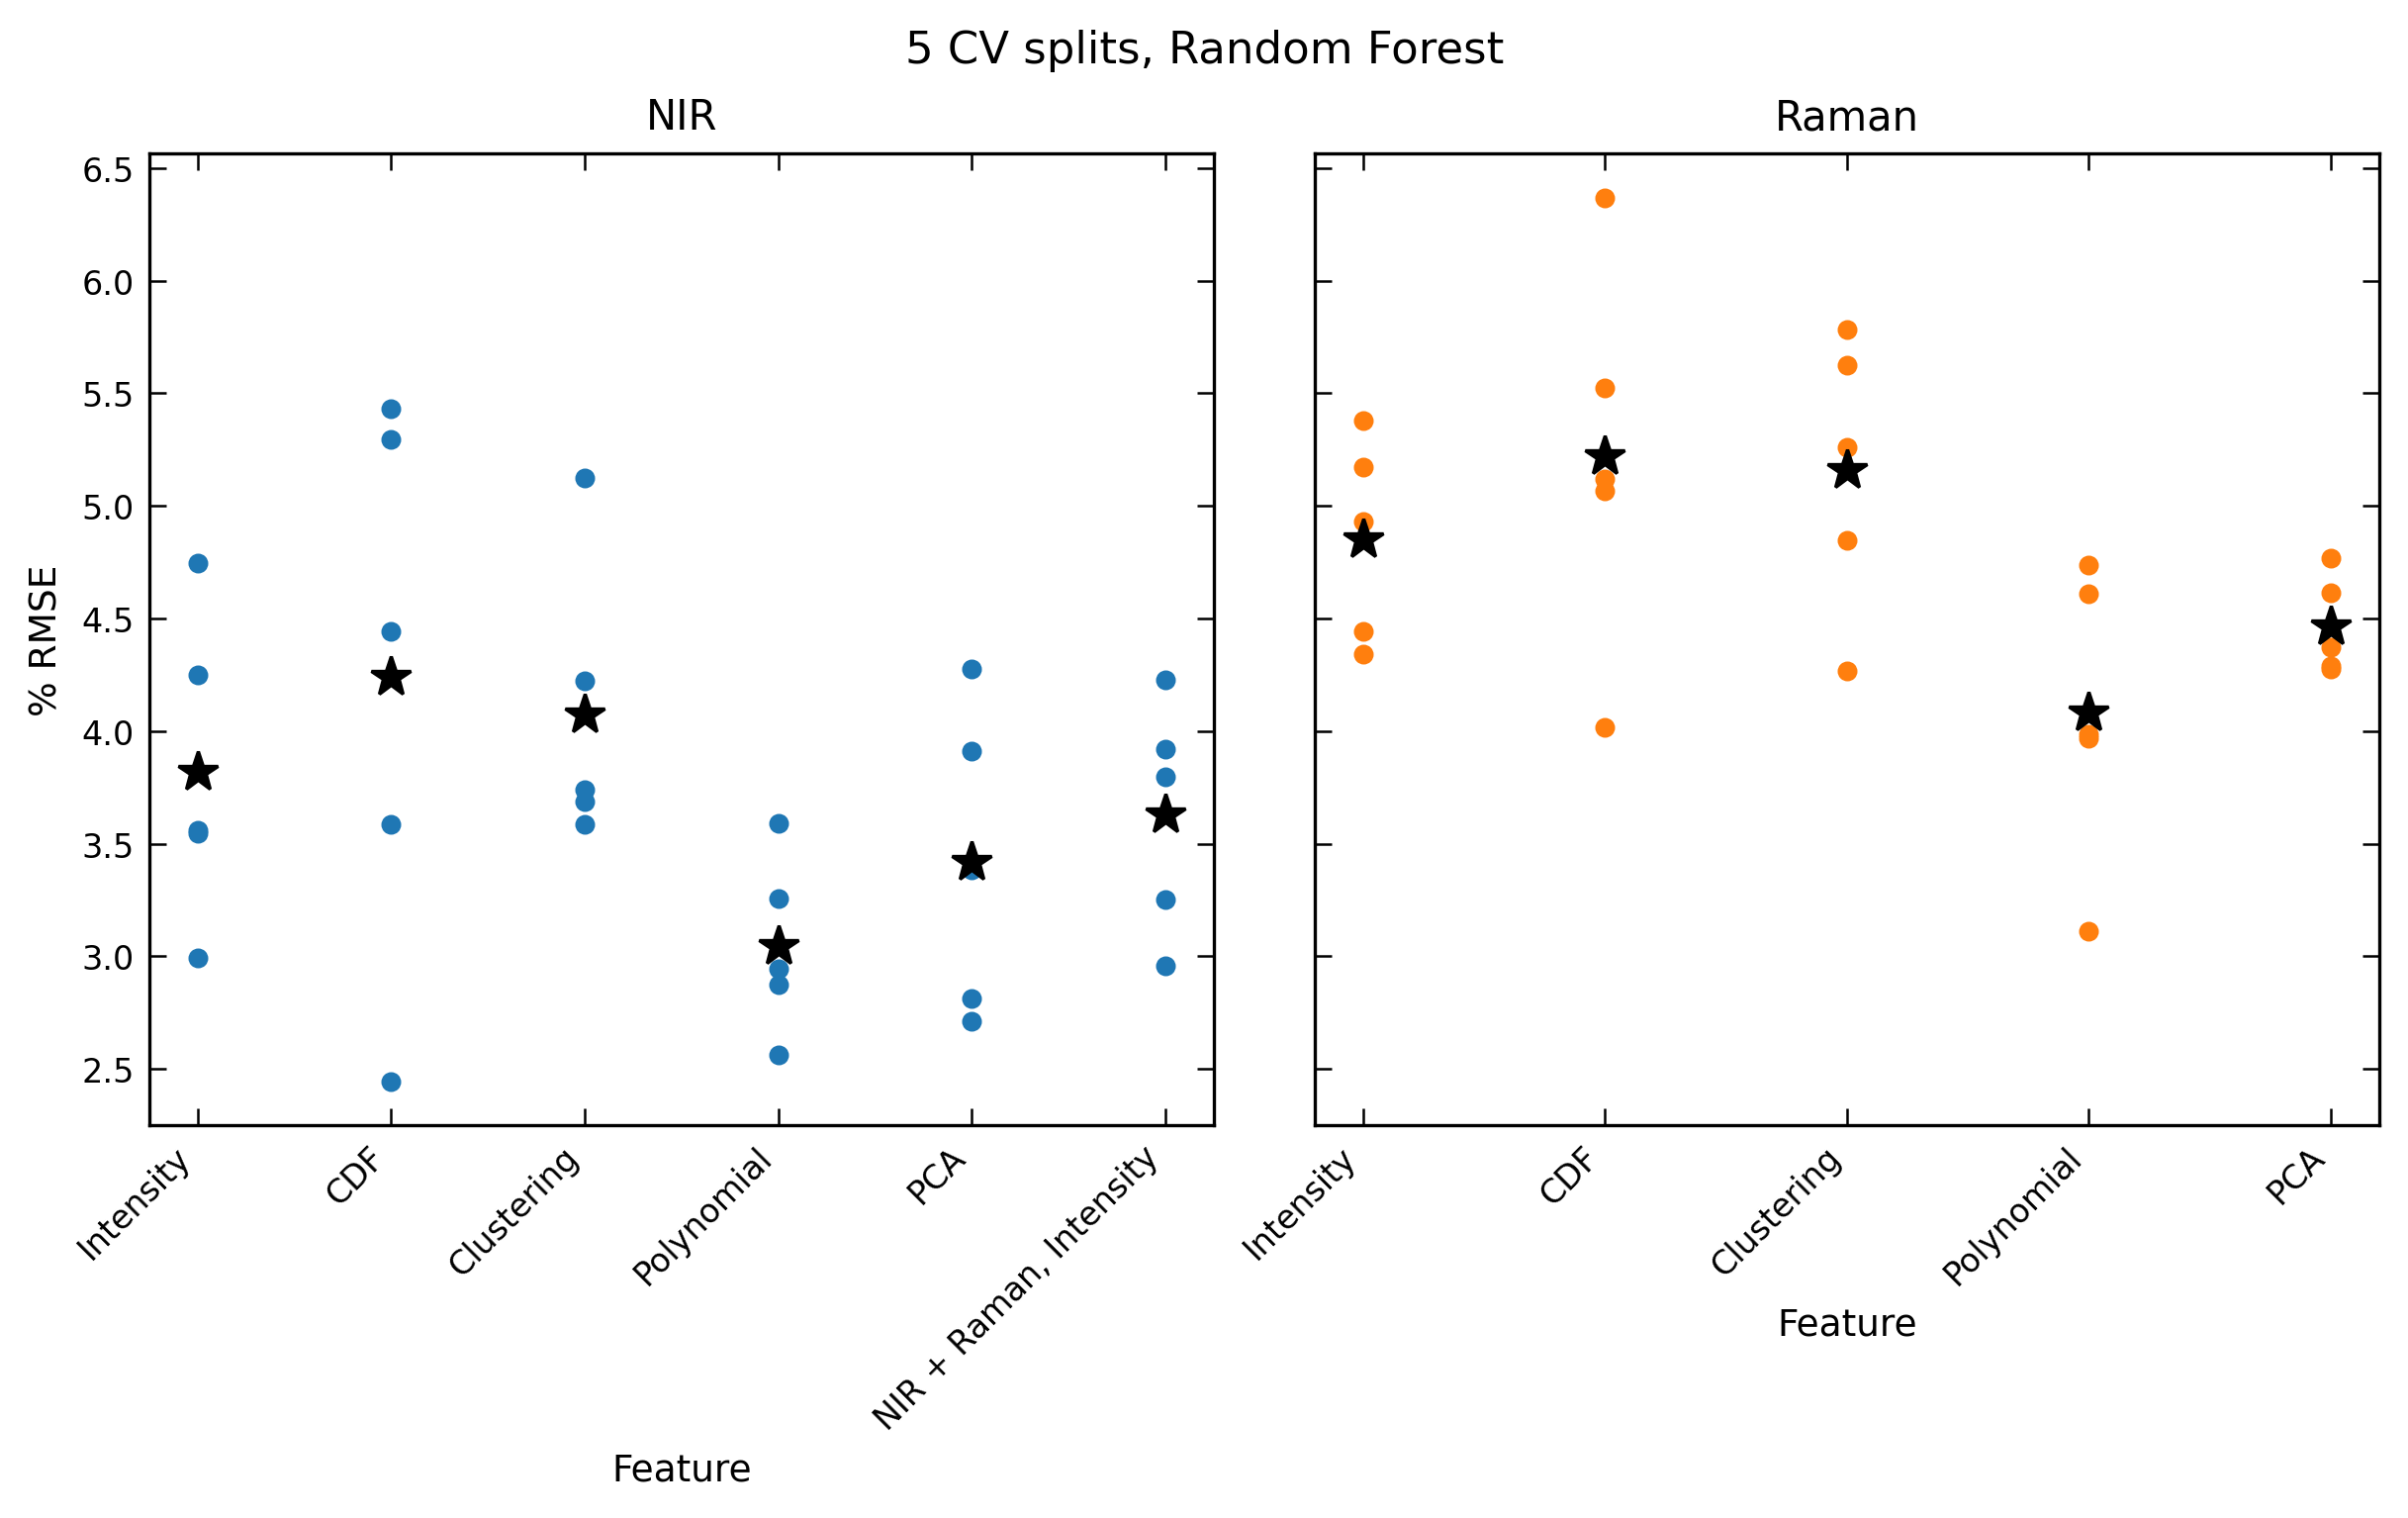

In [57]:
f, axs = plt.subplots(1,2, figsize=(8, 5), constrained_layout=True, sharey=True)
axs = axs.ravel()

for key in cv_results: 
    if 'nir' in key: 
        label = PRETTY_LABELS_DICT[key]
        for result in cv_results[key]: 
            result = result / np.max(ss_f.br) * 100 
            axs[0].plot(label.replace('NIR, ', ''), result, marker='o', color='tab:blue')
        axs[0].set_title('NIR')
        axs[0].plot(label.replace('NIR, ', ''), np.mean(cv_results[key]/ np.max(ss_f.br)) * 100, 'k*', markersize=10)
    else: 
        label = PRETTY_LABELS_DICT[key]
        for result in cv_results[key]: 
            result = result / np.max(ss_f.br) * 100 
            axs[1].plot(label.replace('Raman, ', ''), result, marker='o', color='tab:orange')
        axs[1].set_title('Raman')
        axs[1].plot(label.replace('Raman, ', ''), np.mean(cv_results[key]/ np.max(ss_f.br)) * 100, 'k*', markersize=10)
f.suptitle('5 CV splits, Random Forest')
for ax in axs: 
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    ax.set_xlabel('Feature')
axs[0].set_ylabel('% RMSE')
plt.savefig('Figures/Grapes_RF_CV.pdf')


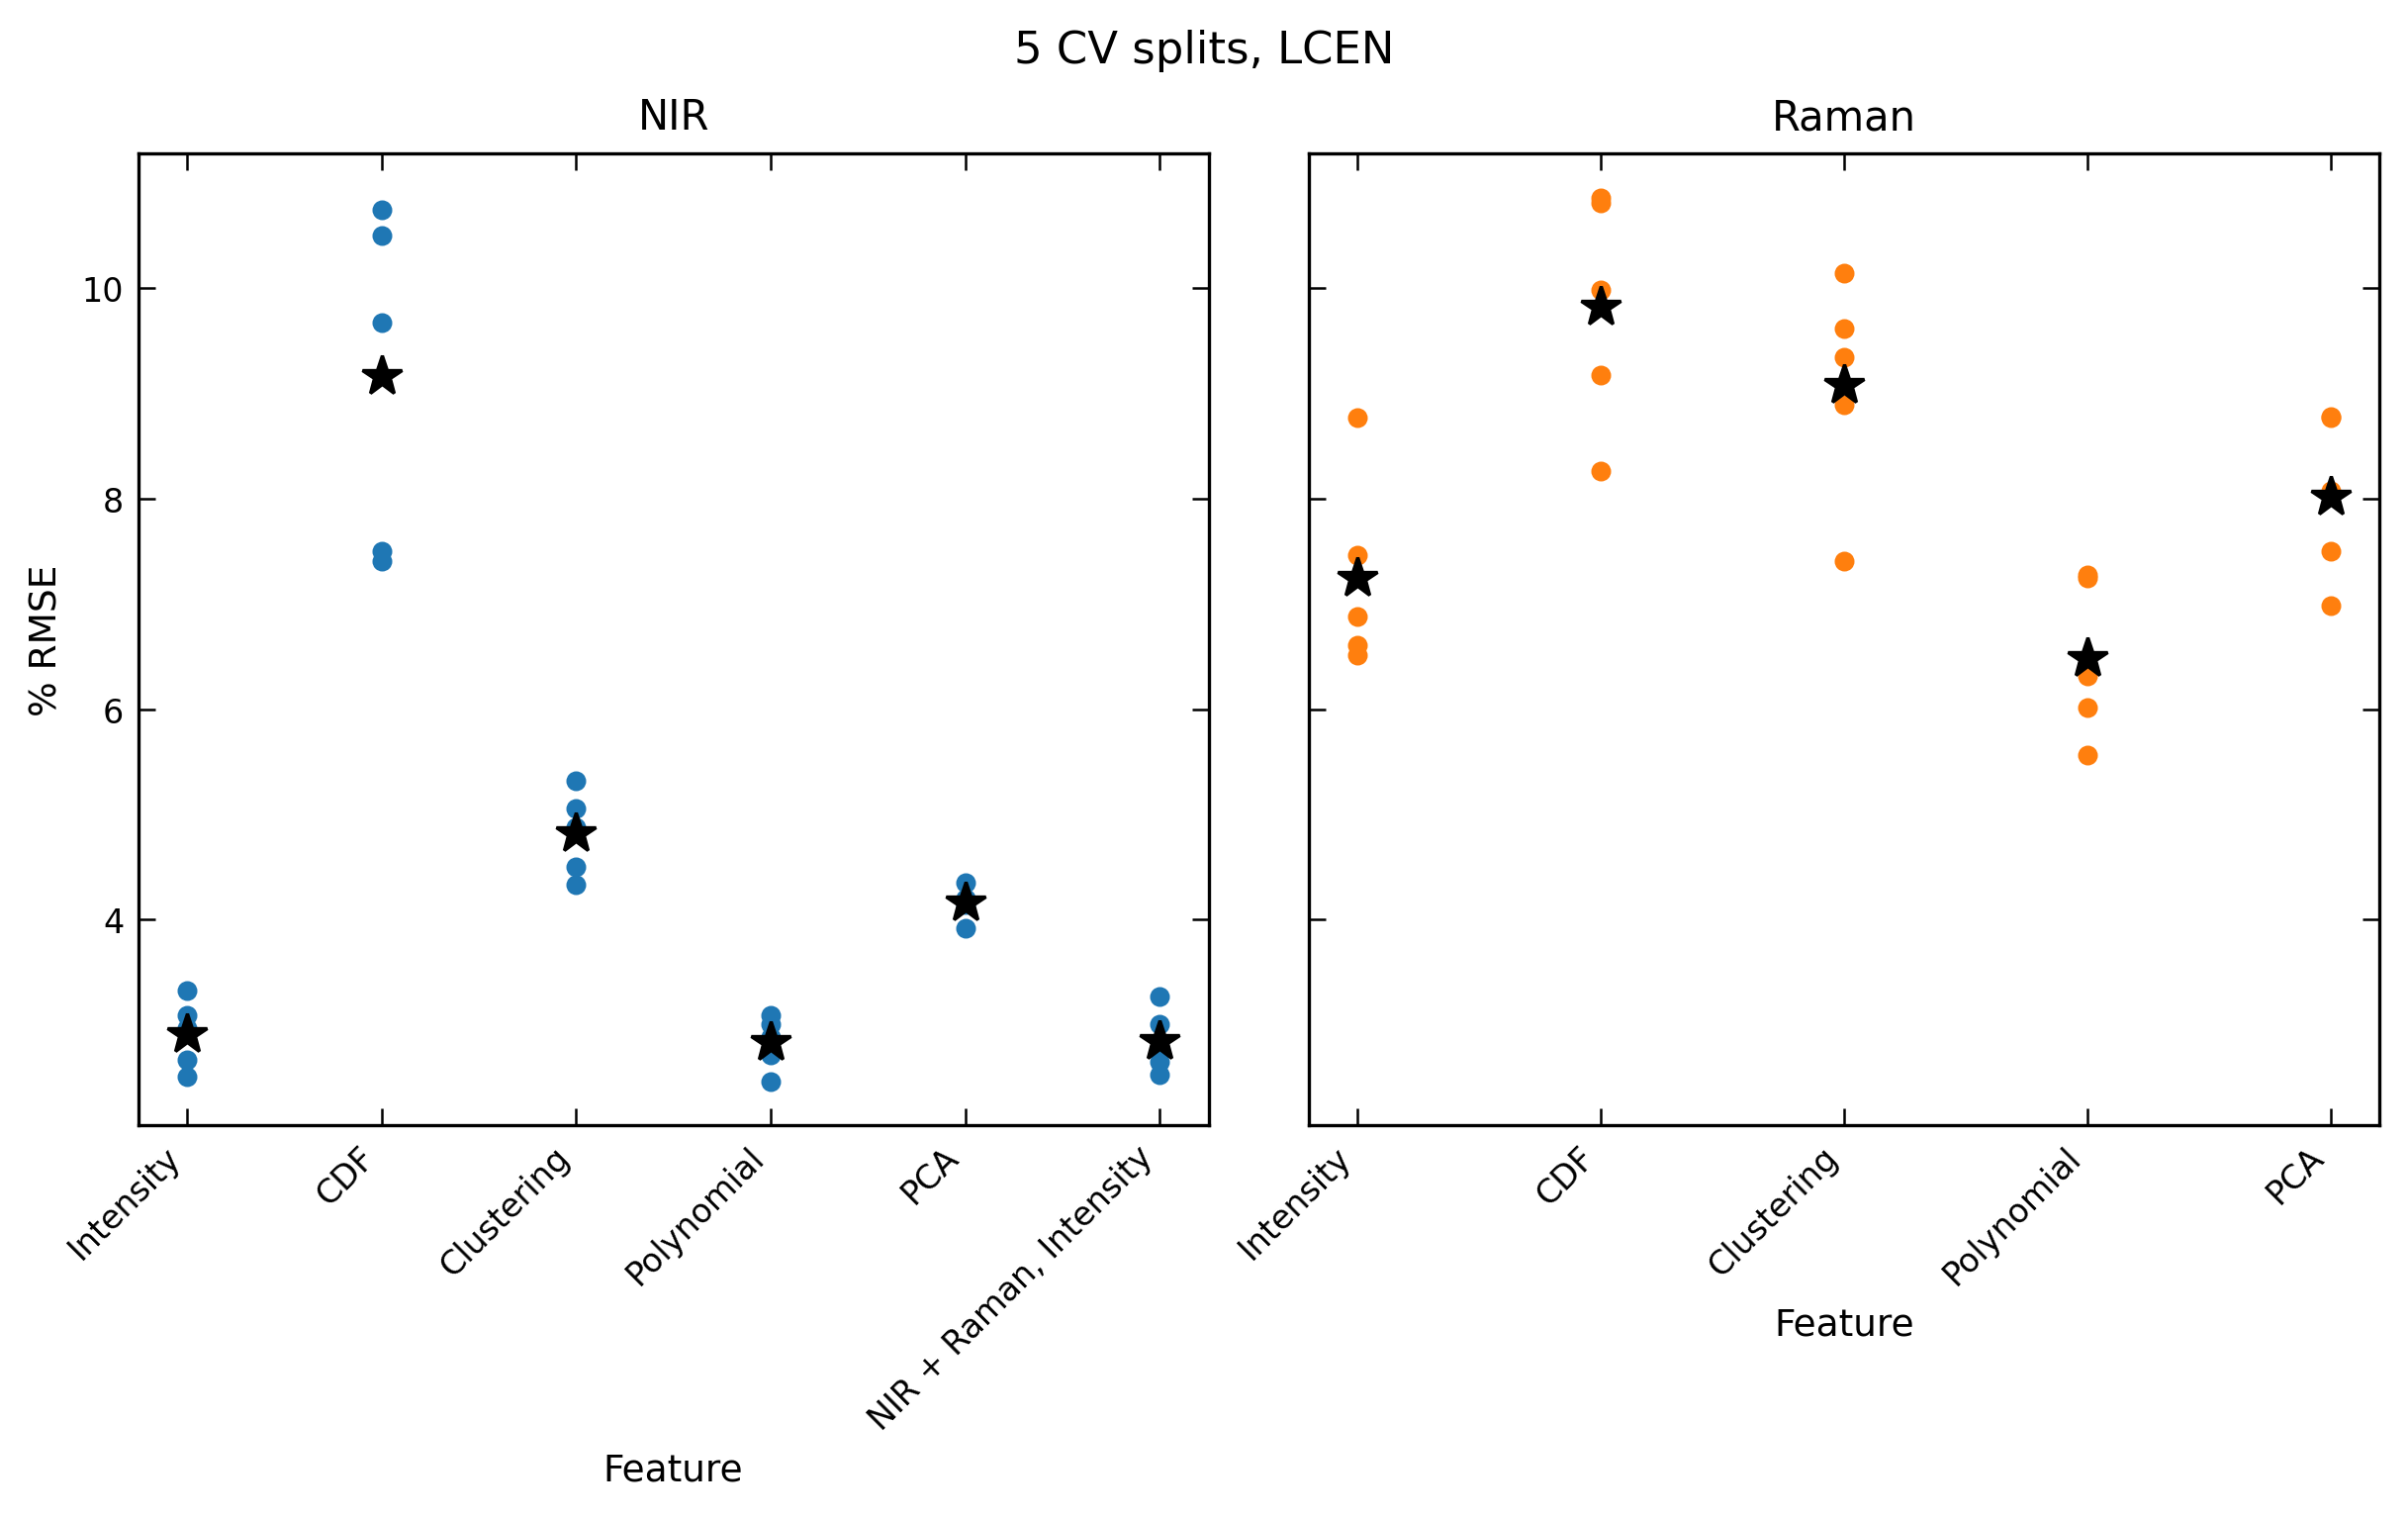

In [58]:
f, axs = plt.subplots(1,2, figsize=(8, 5), constrained_layout=True, sharey=True)
axs = axs.ravel()

for key in cv_results_lcen: 
    if 'nir' in key: 
        label = PRETTY_LABELS_DICT[key]
        for result in cv_results_lcen[key]: 
            result = result / np.max(ss_f.br) * 100 
            axs[0].plot(label.replace('NIR, ', ''), result, marker='o', color='tab:blue')
        axs[0].set_title('NIR')
        axs[0].plot(label.replace('NIR, ', ''), np.mean(cv_results_lcen[key]/ np.max(ss_f.br)) * 100, 'k*', markersize=10)
    else: 
        label = PRETTY_LABELS_DICT[key]
        for result in cv_results_lcen[key]: 
            result = result / np.max(ss_f.br) * 100 
            axs[1].plot(label.replace('Raman, ', ''), result, marker='o', color='tab:orange')
        axs[1].set_title('Raman')
        axs[1].plot(label.replace('Raman, ', ''), np.mean(cv_results_lcen[key]/ np.max(ss_f.br)) * 100, 'k*', markersize=10)
f.suptitle('5 CV splits, LCEN')
for ax in axs: 
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    ax.set_xlabel('Feature')
axs[0].set_ylabel('% RMSE')
plt.savefig('Figures/Grapes_LCEN_CV.pdf')


### Random Variable Control Experiment

Append a Gaussian random variable as an extra feature to each feature
matrix, then retrain all models on the augmented data. This provides a
baseline threshold: any real feature selected less prominently than the
random variable carries no meaningful signal.

In [59]:
import copy
ss_rv = SpectraScope(XF, br, specnames=['nir', 'rm'], yname='br', random_seed=10)
ss_rv.add_x_axis('rm', raman_wls)
ss_rv.add_x_axis('nir', nir_wls[selected_wls])
ss_rv.add_spectral_feature('rm', 'pointwise_features', xrange=ss_rv.rm_xaxis)
ss_rv.add_spectral_feature('rm', 'polynomial_featuresall')
ss_rv.add_spectral_feature('rm', 'featureagg', n_clusters=15)
ss_rv.add_spectral_feature('rm', 'pca', n_components=15)
ss_rv.add_spectral_feature('rm', 'cdf')
ss_rv.add_spectral_feature('rm', 'cwt')

ss_rv.add_spectral_feature('nir', 'pointwise_features', xrange=ss_rv.nir_xaxis)
ss_rv.add_spectral_feature('nir', 'polynomial_featuresall')
ss_rv.add_spectral_feature('nir', 'featureagg', n_clusters=15)
ss_rv.add_spectral_feature('nir', 'pca', n_components=15)
ss_rv.add_spectral_feature('nir', 'cdf')
ss_rv.add_spectral_feature('nir', 'cwt')
ss_rv.add_spectral_feature('nir', 'fft_features', xrange=ss_rv.nir_xaxis)

## combine modalities 
ss_rv.combine_feature('rm_pointwise_features', 'nir_pointwise_features')

for feat in ss_rv.generated_features: 
    feat_arr = getattr(ss_rv, feat)
    random_var = np.random.randn(feat_arr.shape[0], 1)
    feat_arr = np.append(feat_arr, random_var, axis=1)
    setattr(ss_rv, f'{feat}', feat_arr)

saving to /examples/models, change save_path kwarg if youd like to change


In [60]:
feats = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']#, 'pointwise_features_trans',] #uncomment for nonlinear transformations
from sklearn.metrics import root_mean_squared_error
for spec in ss_rv.specnames:
    for feat in feats: 
        attr_name = f'{spec}_{feat}'
        ss_rv.do_sk(attr_name, 'br', 0.25, use_pipeline=True, **RF_kwargs)
        ss_rv.do_sk(attr_name, 'br', 0.25, use_pipeline=False, **Linear_kwargs)
        ss_rv.do_sk(attr_name, 'br', 0.25, use_pipeline=True, **Lasso_kwargs)
ss_rv.do_sk('rm_nir_pointwise_features', 'br', 0.25, use_pipeline=True, **RF_kwargs)
ss_rv.do_sk('rm_nir_pointwise_features', 'br', 0.25, use_pipeline=False, **Linear_kwargs)
ss_rv.do_sk('rm_nir_pointwise_features', 'br', 0.25, use_pipeline=True, **Lasso_kwargs)

already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted


In [61]:
for spec in ss_rv.specnames:
    for feat in feats: 
        attr_name = f'{spec}_{feat}'
        try: 
            ss_rv.do_sk(attr_name, 'br', 0.25, use_pipeline=False, **fused_kwargs)
        except RuntimeError: 
            print(spec, feat)
            continue

ss_rv.do_sk('nir_pointwise_features', 'br', 0.25, use_pipeline=False, estimator=FusedLasso(alpha=0.5), metric=mean_squared_error)

already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted


In [62]:
feats_lcen = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']

for spec in ss_rv.specnames:
    for feat in feats_lcen: 
        attr_name = f'{spec}_{feat}'
        ss_rv.do_LCEN(attr_name, 'br', 0.25, **lcen_kwargs)

ss_rv.do_LCEN('rm_nir_pointwise_features', 'br', 0.25, **lcen_kwargs)

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.5640 | Mean relative error = 0.0272
Test set : RMSE = 1.0741 | Mean relative error = 0.0496
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 2.3157 | Mean relative error = 0.1023
Test set : RMSE = 2.2547 | Mean relative error = 0.0931
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its resul

## Where Does the Random Variable End Up?

Inspect the RF feature importance and LCEN coefficient assigned to the
appended random variable in each model. Features above this threshold
are considered informative.

In [63]:
# where does the random variable end up? 
rv_importance = {}
for feat in ss_rv.generated_features: 
    # RF models
    try: 
        print('--------------------------------')
        print(feat)
        rf = getattr(ss_rv, f'{feat}_br_RandomForestRegressor')['P'][0]
        feature_importances = rf.best_estimator_.feature_importances_
        importance_rv = feature_importances[-1]
        greater = np.where(feature_importances > importance_rv)[0]
        print('RF, random variable feat importance : \t', importance_rv, )#len(greater))
        rv_importance[f'{feat}_br_RandomForestRegressor'] = importance_rv 
    except: 
        continue
    #LCEN models 
    try: 
        model_params = getattr(ss_rv, f'{feat}_br_LCEN')['model_params']
        model_params = np.array(model_params)
        n_real_features = getattr(ss_rv, feat).shape[1] - 1  # last col is random
        rv_name = f'x{n_real_features}'
        
        rv_coef = 0.0  # default: LCEN didn't select it
        for name, val in model_params:
            if name == rv_name:
                rv_coef = abs(float(val))
                break
        
        print(f'LCEN, random variable abs coef: {rv_coef}')
        rv_importance[f'{feat}_br_LCEN'] = rv_coef
    except Exception as e:
        print(e)
        continue
    print('--------------------------------')

    #Lasso models 

    #Fused Lasso models 

    #Linear models 

--------------------------------
rm_pointwise_features
RF, random variable feat importance : 	 0.026835770896124225
LCEN, random variable abs coef: 0.10970336060505585
--------------------------------
--------------------------------
rm_polynomial_featuresall
RF, random variable feat importance : 	 0.00652251508135611
LCEN, random variable abs coef: 0.0
--------------------------------
--------------------------------
rm_featureagg
RF, random variable feat importance : 	 0.0949692330877014
LCEN, random variable abs coef: 0.0
--------------------------------
--------------------------------
rm_pca
RF, random variable feat importance : 	 0.025220428992607184
LCEN, random variable abs coef: 0.0
--------------------------------
--------------------------------
rm_cdf
RF, random variable feat importance : 	 0.05480623162552316
LCEN, random variable abs coef: 0.0
--------------------------------
--------------------------------
rm_cwt
--------------------------------
nir_pointwise_features
R

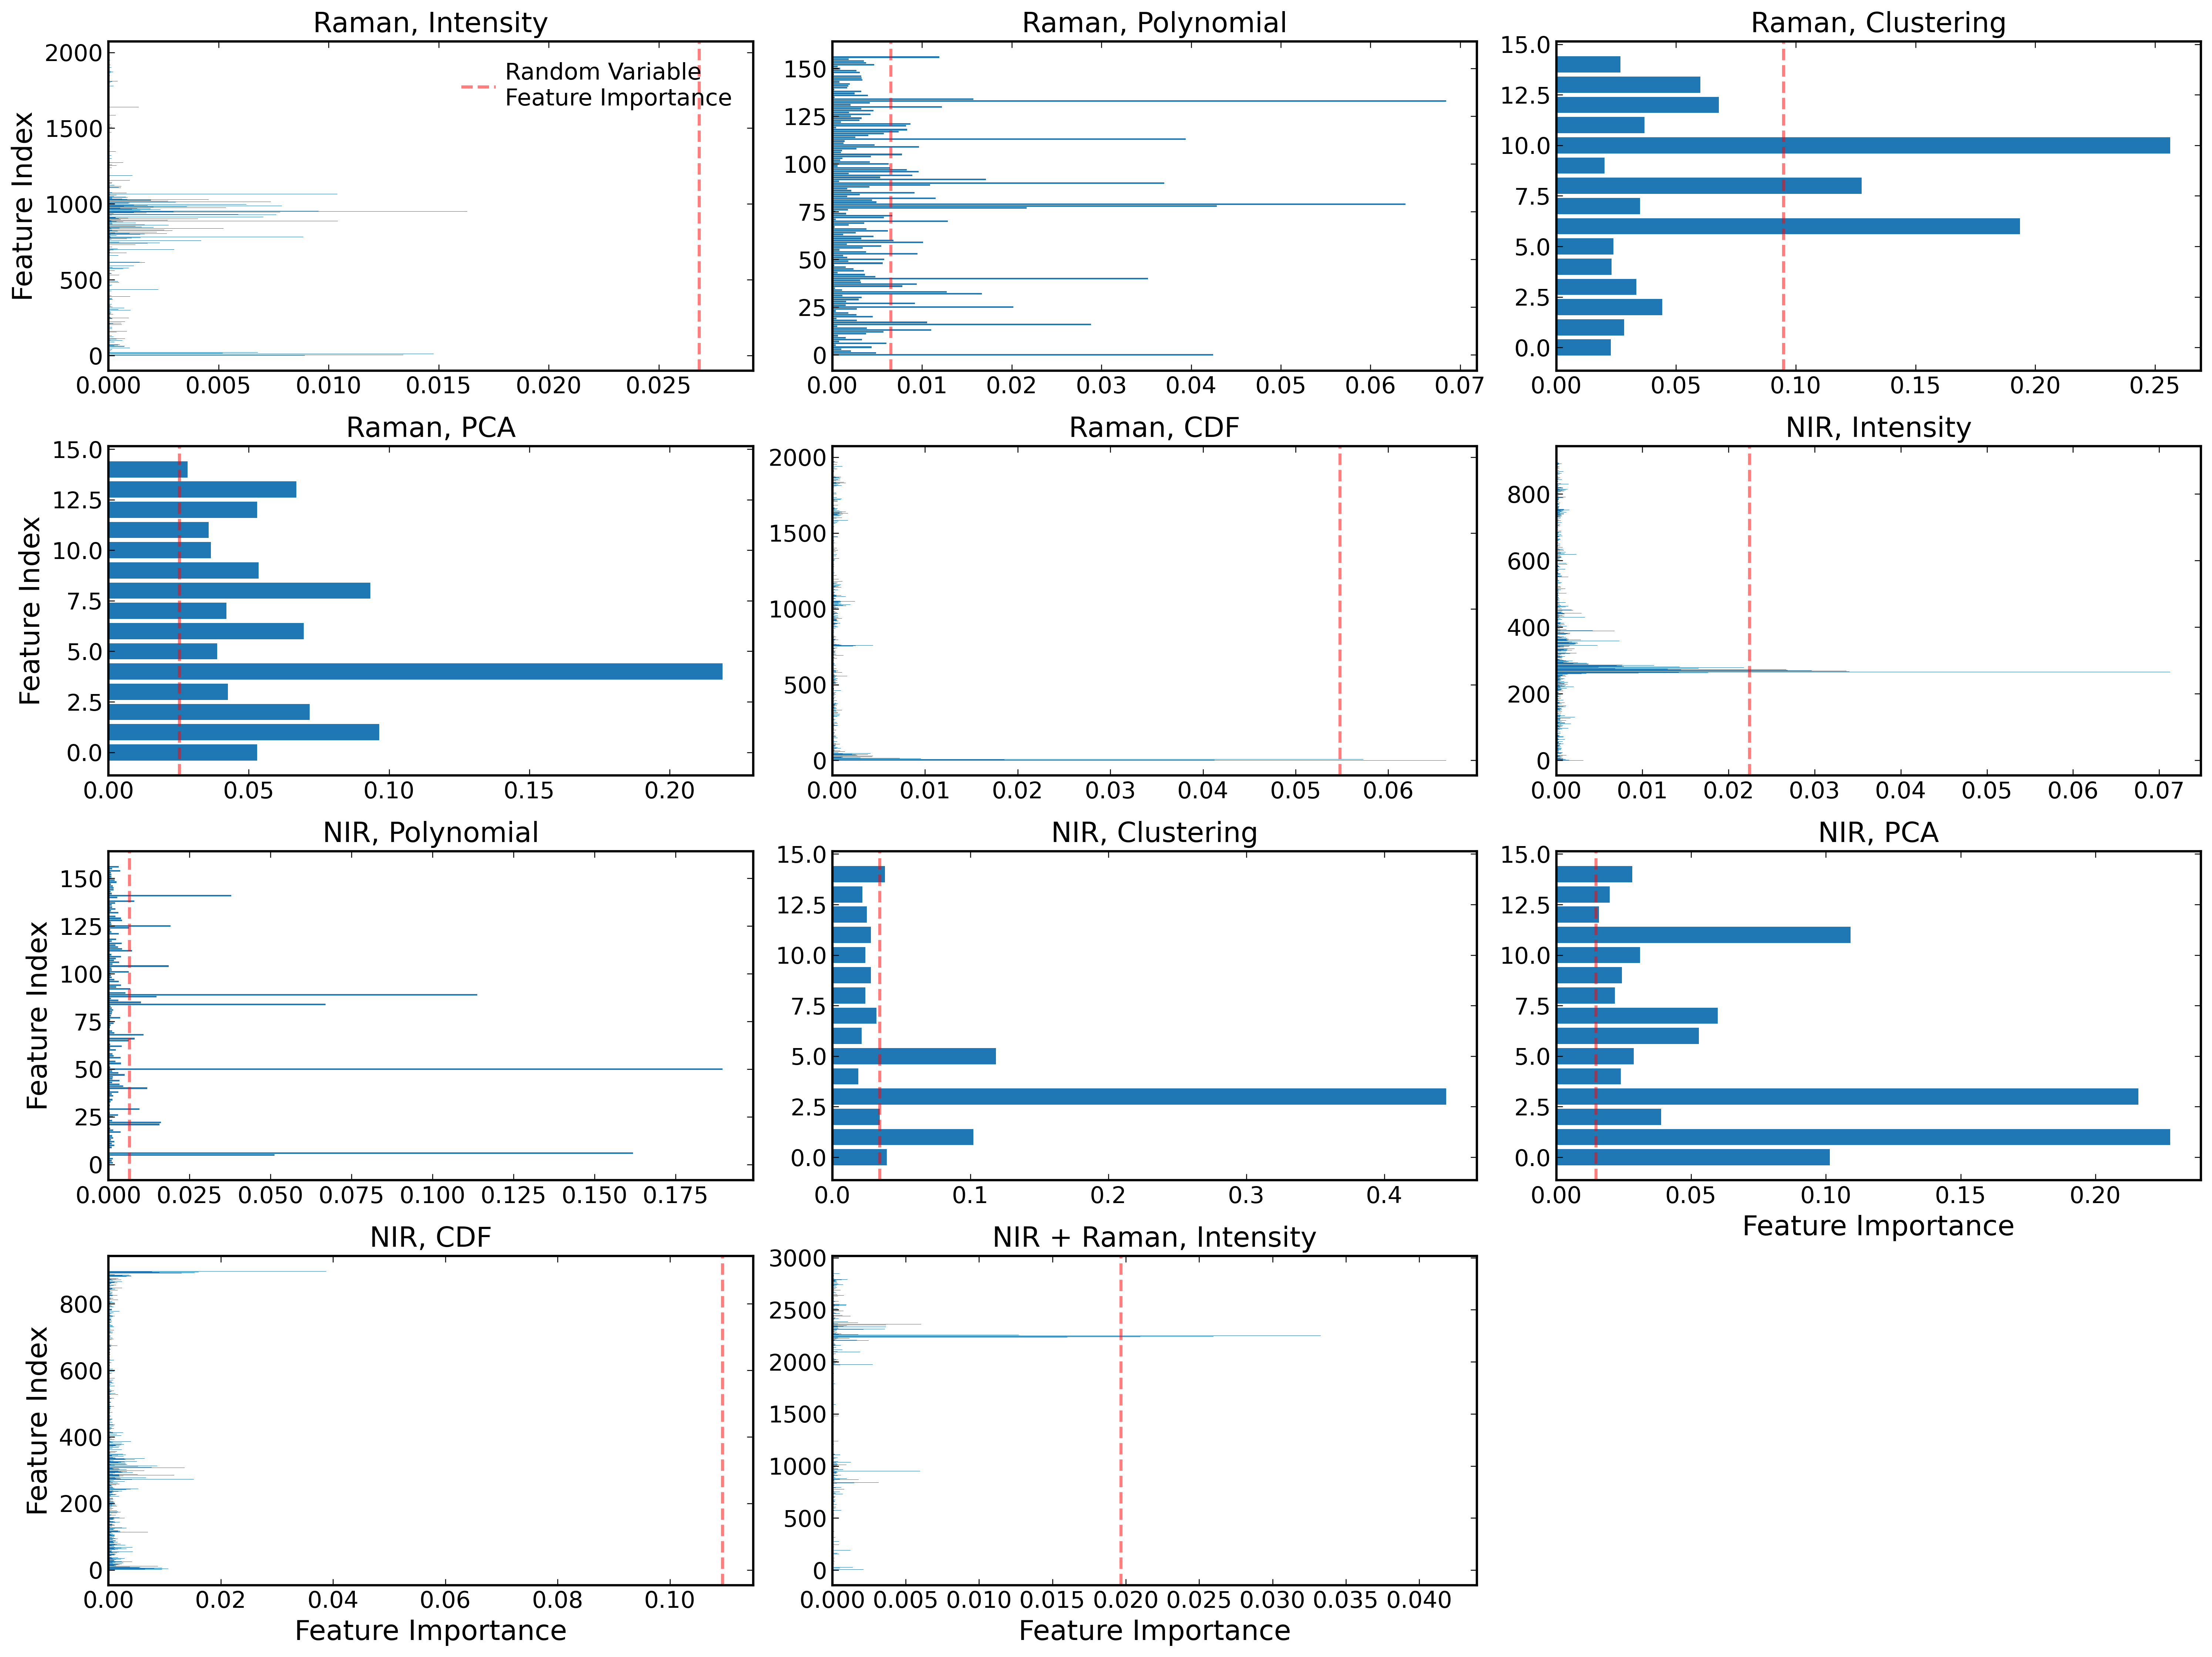

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

attr_list = []
importances_list = []

for attr_name in ss_f.generated_features: 
    try: 
        gs = getattr(ss_f, f'{attr_name}_br_RandomForestRegressor')['P'][0]
        feature_importances = gs.best_estimator_.feature_importances_
        importances_list.append(feature_importances)
        attr_list.append(attr_name)
    except Exception as e:
        continue

n_attrs = len(attr_list)
fig, axs = plt.subplots(
    4,3, figsize=(20,15), sharey=False, constrained_layout=True
)

axs = axs.ravel()

for i, (attr_name, feature_importances) in enumerate(zip(attr_list, importances_list)):
    ax = axs[i]

    ax.barh(range(len(feature_importances)), feature_importances)
    ymin, ymax = ax.get_ylim()
    ax.vlines(rv_importance[f'{attr_name}_br_RandomForestRegressor'], ymin, ymax, color='r', linestyle='--', linewidth=2, alpha=0.5, label = 'Random Variable \nFeature Importance')
    ax.set_ylim(ymin, ymax)
    # ax.set_xticks(range(len(topk_idx)))
    # ax.set_xticklabels(topk_idx, rotation=90)

    # print(len(top_importances))
    ax.set_title(PRETTY_LABELS_DICT[attr_name], fontsize=18)
    # ax.set_xlabel("Feature Index", fontsize=15)
    # ax.set_ylabel("Feature Importance", fontsize=15)
    ax.tick_params(axis='both', labelsize=15)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

axs[0].legend(fontsize=15)
axs[0].set_ylabel("Feature Index", fontsize=18)
axs[3].set_ylabel("Feature Index", fontsize=18)
axs[6].set_ylabel("Feature Index", fontsize=18)
axs[9].set_ylabel("Feature Index", fontsize=18)
axs[8].set_xlabel("Feature Importance", fontsize=18)
axs[9].set_xlabel("Feature Importance", fontsize=18)
axs[10].set_xlabel("Feature Importance", fontsize=18)
axs[11].axis('off')
plt.tight_layout()


plt.savefig('Figures/Grapes_RF_feature_importance.svg', dpi=300)
plt.savefig('Figures/Grapes_RF_feature_importance.pdf', dpi=300)

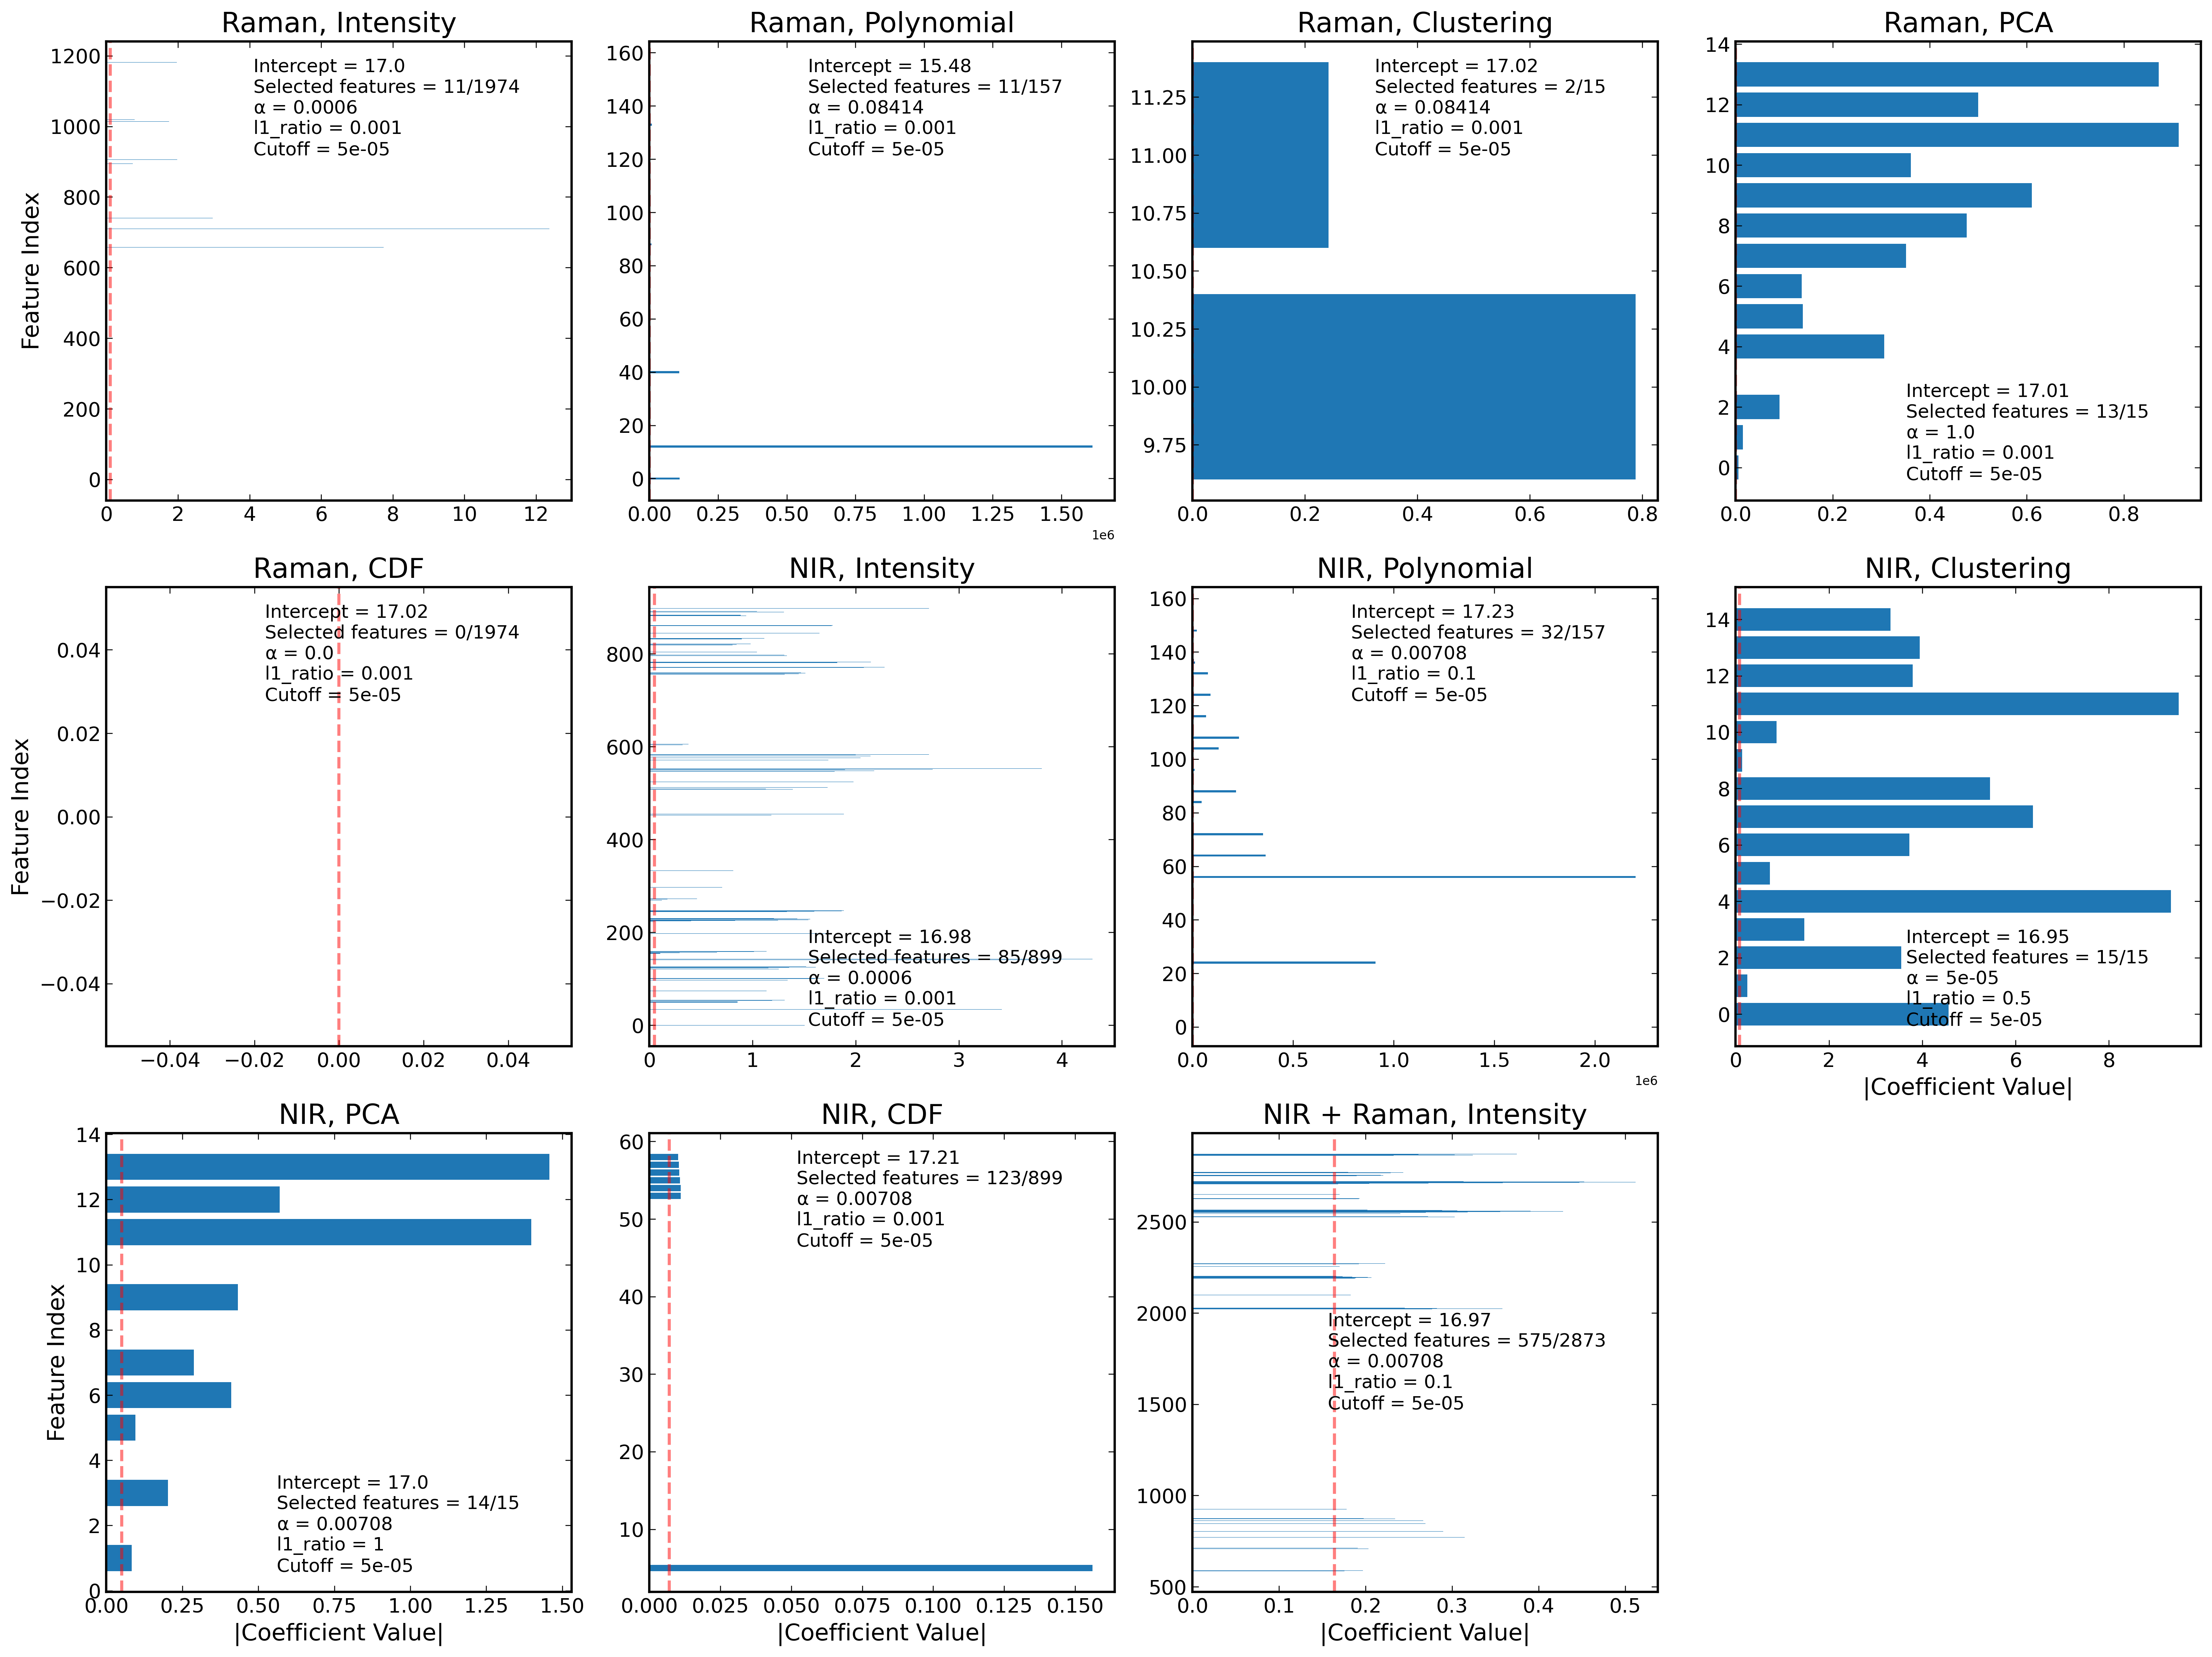

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

attr_list = []
importances_list = []
coef_names = []
alpha_list = []
l1_list = []
cutoff_list = []

for attr_name in ss_f.generated_features: 
    try: 
        model_params = getattr(ss_f, f'{attr_name}_br_LCEN')['model_params']
        model_params = np.array(model_params)
        coefs = model_params[:,1]
        coefs = np.array([float(c) for c in coefs])
        coefs = np.abs(coefs)
        attr_list.append(attr_name)
        importances_list.append(coefs)
        coef_names.append(model_params[:,0])
        l1 = getattr(ss_f, f'{attr_name}_br_LCEN')['model_hyper']['l1_ratio']
        alpha = getattr(ss_f, f'{attr_name}_br_LCEN')['model_hyper']['alpha']
        cutoff = getattr(ss_f, f'{attr_name}_br_LCEN')['model_hyper']['cutoff']
        alpha_list.append(alpha)
        l1_list.append(l1)
        cutoff_list.append(cutoff)
    except Exception as e:
        continue

n_attrs = len(attr_list)
fig, axs = plt.subplots(
    3, 4, figsize=(20,15), sharey=False, constrained_layout=True
)

axs = axs.ravel()

for j, (attr_name, feature_importances) in enumerate(zip(attr_list, importances_list)):
    ax = axs[j]
    par_names = coef_names[j]
    
    n_features = getattr(ss_f, attr_name).shape[-1]
    lcen_arr = np.zeros(n_features)
    
    for name, val in zip(par_names, feature_importances):
        if name == 'intercept':
            intercept = val 
            continue
        idx = int(name.replace('x', ''))
        lcen_arr[idx] = val
    rv_val = rv_importance[f'{attr_name}_br_LCEN']
    idx_above_rv = np.where(lcen_arr > rv_val)[0]
    ax.barh(idx_above_rv, lcen_arr[idx_above_rv])
    ymin, ymax = ax.get_ylim()
    xmin, xmax = ax.get_xlim()
    ax.vlines(rv_val, ymin, ymax, color='r', linestyle='--', linewidth=2, alpha=0.5, label='Random Variable\nCoefficient')
    ax.set_ylim(ymin, ymax)
    # ax.text(0.4, 0.25, f'Intercept={np.round(intercept, 2)}', transform=ax.transAxes,
    #         ha='left', va='top', fontsize=12)
    # ax.text(0.4, 0.15, f'selected={len(lcen_arr.nonzero()[0])}/{n_features}', transform=ax.transAxes,
    #         ha='left', va='top', fontsize=12)
    # ax.set_xticks(range(len(topk_idx)))
    # ax.set_xticklabels(topk_idx, rotation=90)
    # print(len(top_importances))
    ax.set_title(PRETTY_LABELS_DICT[attr_name], fontsize=18)
    # ax.set_xlabel("Feature Index", fontsize=15)
    # ax.set_ylabel("Feature Importance", fontsize=15)
    ax.tick_params(axis='both', labelsize=13)

    intercept_str = f"Intercept = {np.round(intercept, 2)}"
    n_selected = len(lcen_arr.nonzero()[0])
    n_selected_str = f"Selected features = {n_selected}/{n_features}"
    alpha_val = alpha_list[j] if j < len(alpha_list) else None
    l1_val = l1_list[j] if j < len(l1_list) else None
    cutoff_val = cutoff_list[j] if j < len(cutoff_list) else None
    alpha_str = f"$\\alpha$ = {np.round(alpha_val, 5) if alpha_val is not None else 'N/A'}"
    l1_str = f"l1_ratio = {np.round(l1_val, 3) if l1_val is not None else 'N/A'}"
    cutoff_str = f"Cutoff = {cutoff_val:g}" if cutoff_val is not None else "Cutoff = N/A"
    legend_text = (
        f"{intercept_str}\n"
        f"{n_selected_str}\n"
        f"{alpha_str}\n"
        f"{l1_str}\n"
        f"{cutoff_str}"
    )
    # ax.legend([legend_text], fontsize=10, frameon=True, markerfirst=Tru, handletextpad=1.2, handlelength=1.0, markerscale=1.0, loc='best', borderaxespad=0, fancybox=True, shadow=False, scatterpoints=1, numpoints=1)
    # Also add a legend marker (dot)
    from matplotlib.lines import Line2D
    ax.legend([Line2D([0], [0], marker='o', color='w', markerfacecolor='k', markersize=0)], [legend_text], fontsize=12, frameon=False, markerfirst=False)
    
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

# axs[0].legend(fontsize=10)
axs[0].set_ylabel("Feature Index", fontsize=15)
axs[4].set_ylabel("Feature Index", fontsize=15)
axs[8].set_ylabel("Feature Index", fontsize=15)
axs[8].set_xlabel("|Coefficient Value|", fontsize=15)
axs[9].set_xlabel("|Coefficient Value|", fontsize=15)
axs[10].set_xlabel("|Coefficient Value|", fontsize=15)
axs[7].set_xlabel("|Coefficient Value|", fontsize=15)

axs[-1].axis('off')
plt.tight_layout()

plt.savefig('Figures/Grapes_LCEN_feature_importance.svg', dpi=300)
plt.savefig('Figures/Grapes_LCEN_feature_importance.pdf', dpi=300)

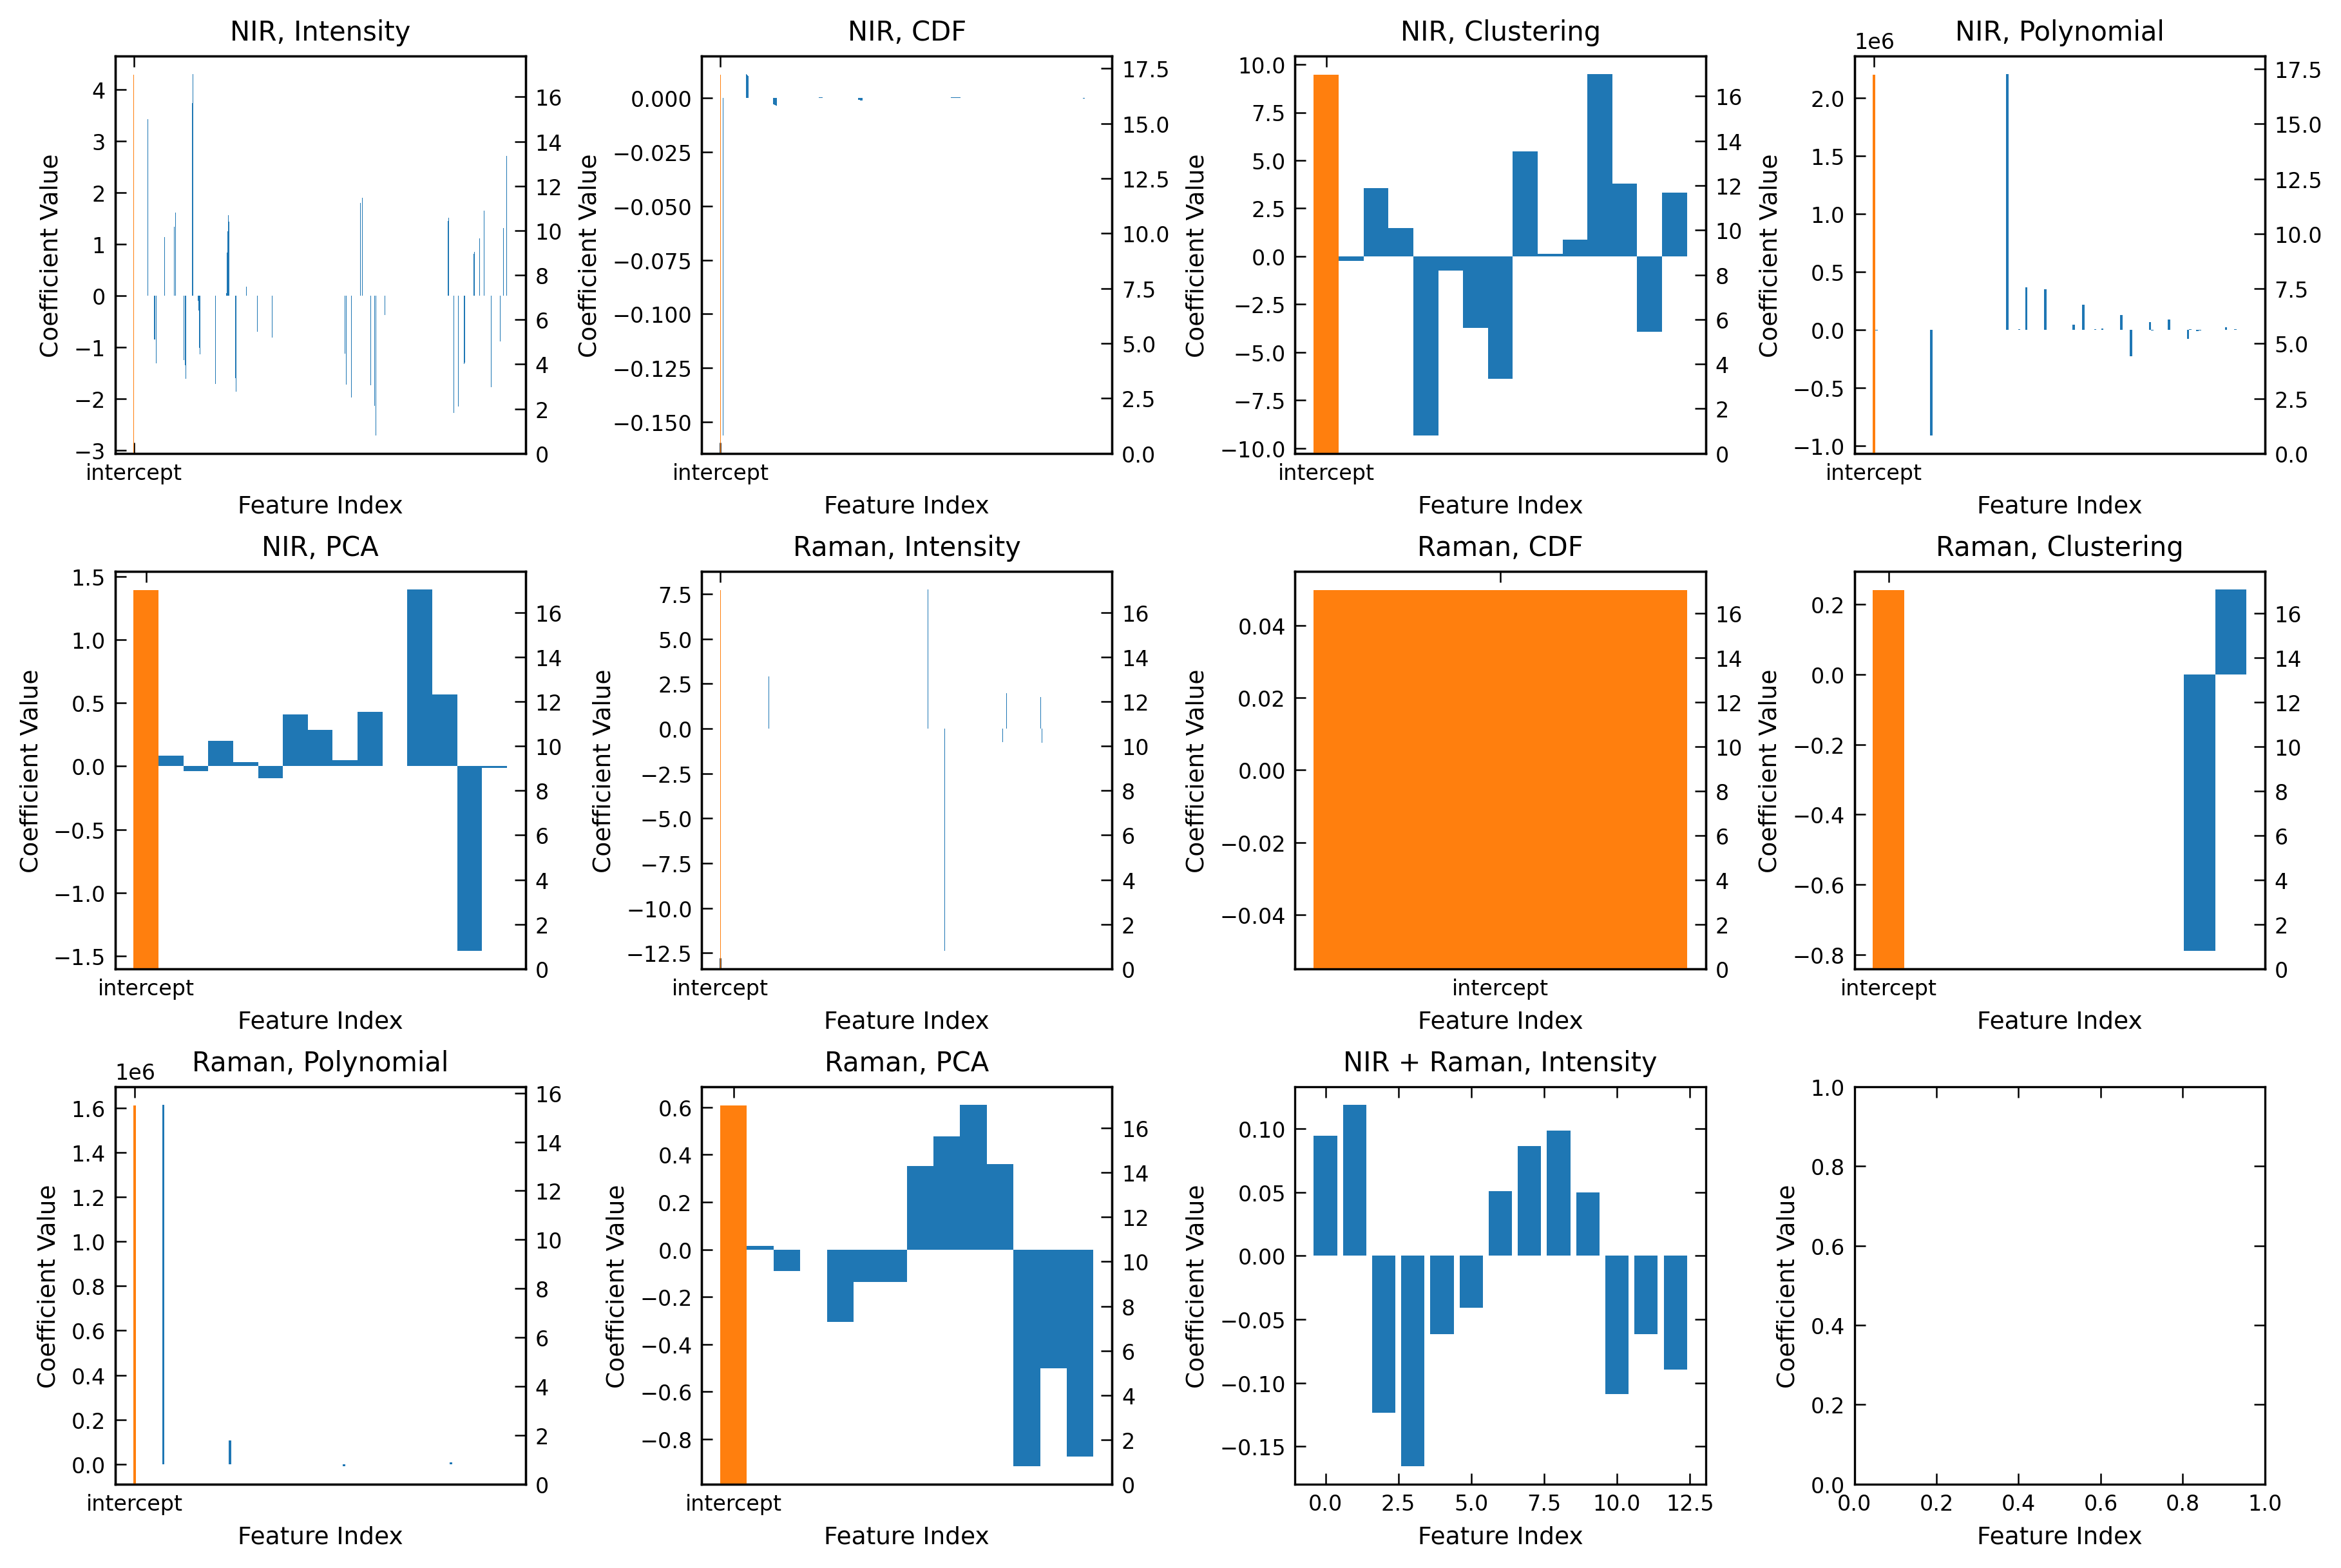

In [66]:
f, axs = plt.subplots(3,4, figsize=(12,8), constrained_layout=True, sharey=False)
axs = axs.ravel()
i = 0 
for spec in ss_f.specnames:
    for feat in feats: 
        X = getattr(ss_f, f'{spec}_{feat}')
        model_params = np.array(getattr(ss_f, f'{spec}_{feat}_br_LCEN')['model_params'])
        pars = model_params[:,0]
        vals = model_params[:,1]
        if 'intercept' in pars: 
            ax_twin = axs[i].twinx()
            ax_twin.bar('intercept', float(vals[0]), color='tab:orange', width=1)
            vals = [float(v) for v in vals[1:]]
            # pars = pars[1:]
            pars = [float(p.replace('x', '0')) for p in pars[1:]]
            # print(intercept)

        axs[i].bar(pars, vals, color='tab:blue', width=1)
        axs[i].set_title(PRETTY_LABELS_DICT[f'{spec}_{feat}'])
        i +=1


X = getattr(ss_f, f'rm_nir_pointwise_features')
feat_importances = getattr(ss_f, f'{spec}_{feat}_br_LCEN')['final_model'].coef_
axs[i].bar(np.arange(len(feat_importances)), feat_importances)
axs[i].set_title(PRETTY_LABELS_DICT['rm_nir_pointwise_features'])

for ax in axs: 
    ax.set_xlabel('Feature Index')
    ax.set_ylabel('Coefficient Value')
plt.savefig('Figures/Grapes_RF_LCEN_vals.pdf')


In [67]:
selected_r = {'RF_r':{}, 'LCEN_r':{}}
ylabel = '_br'
models = ['_LCEN', '_RandomForestRegressor']
from sklearn.feature_selection import r_regression
from spectrascope.utils import LCEN_selected_features
for feat in ss_f.generated_features: 
    for model in models: 
        if hasattr(ss_f, feat + ylabel + model): 
            trained_model = getattr(ss_f, feat + ylabel + model)
            if model == '_LCEN': 
                vals, selected_features = LCEN_selected_features(trained_model, -1)
                if len(selected_features) > 0 :
                    selected_X = getattr(ss_f, feat)[:,selected_features]
                    r = r_regression(selected_X, ss_f.br)
                    selected_r['LCEN_r'][feat] = r
                    num_features = len(r)
                    print(feat, num_features)
                else: 
                    print(f'fitting failed for {feat}')
                    continue

            else:
                if len(selected_features) > 0 : 
                    # RF : choose top 200 features
                    feature_importances = trained_model['P'][0].best_estimator_.feature_importances_
                    selected_features = np.argsort(feature_importances[::-1])[:num_features]
                    selected_X = getattr(ss_f, feat)[:,selected_features]
                    r = r_regression(selected_X, ss_f.br)
                    selected_r['RF_r'][feat] = r
                    print('RF used', feat, num_features)


rm_pointwise_features 10
RF used rm_pointwise_features 10
rm_polynomial_featuresall 10
RF used rm_polynomial_featuresall 10
rm_featureagg 1
RF used rm_featureagg 1
rm_pca 12
RF used rm_pca 12
fitting failed for rm_cdf
nir_pointwise_features 84
RF used nir_pointwise_features 84
nir_polynomial_featuresall 31
RF used nir_polynomial_featuresall 31
nir_featureagg 14
RF used nir_featureagg 14
nir_pca 13
RF used nir_pca 13
nir_cdf 122
RF used nir_cdf 122
rm_nir_pointwise_features 574
RF used rm_nir_pointwise_features 574


In [85]:
r_df = pd.DataFrame({model: {feat: np.max(np.abs(selected_r[model][feat])) for feat in selected_r[model]} for model in selected_r})
temp = pd.DataFrame((results_df.T[['RandomForestRegressor', 'LCEN']]) / np.max(ss_f.br) * 100)
temp = temp.rename(index = lambda x : x.replace('_br', ''))

r_rmse = r_df.join(temp, how='inner')
r_rmse.columns = ['RF_r', 'LCEN_r', 'RF', 'LCEN']
r_rmse = r_rmse.rename(PRETTY_LABELS_DICT, axis=0)
r_rmse.to_csv('Figures/GRAPES_rMAX.csv')

r_df = pd.DataFrame({model: {feat: np.mean(np.abs(selected_r[model][feat])) for feat in selected_r[model]} for model in selected_r})

r_rmse = r_df.join(temp, how='inner')
r_rmse.columns = ['RF_r', 'LCEN_r', 'RF', 'LCEN']
r_rmse = r_rmse.rename(PRETTY_LABELS_DICT, axis=0)
r_rmse.to_csv('Figures/GRAPES_rMEAN.csv')

In [86]:
corr = ss_f.pearson_feature_selection('br', ss_f.generated_features, return_vals=True, k=len(ss_f.generated_features))
corr_df = pd.DataFrame({'r':[np.abs(corr[key]).max() for key in corr]}, index=[key for key in corr])

mif = ss_f.mutual_info_feature_selection('br', ss_f.generated_features, return_vals=True, k=len(ss_f.generated_features))
mif_df = pd.DataFrame({'MIF':[np.abs(mif[key]).max() for key in mif]}, index=[key for key in mif])

merged = corr_df.merge(mif_df, left_index=True, right_index=True)

  0%|          | 0/14 [00:00<?, ?it/s]

100%|██████████| 14/14 [00:13<00:00,  1.00it/s]


In [87]:
temp = pd.DataFrame((results_df.T[['RandomForestRegressor', 'LCEN']]) / np.max(ss_f.br) * 100)
temp = temp.rename(index = lambda x : x.replace('_br', ''))

merged_err = merged.join(temp, how='inner')
merged_err.columns = ['r', 'MIF', 'RF', 'LCEN']
merged_err = merged_err.rename(PRETTY_LABELS_DICT, axis=0)
merged_err.to_csv('Figures/Grapes_rMAX_all.csv')

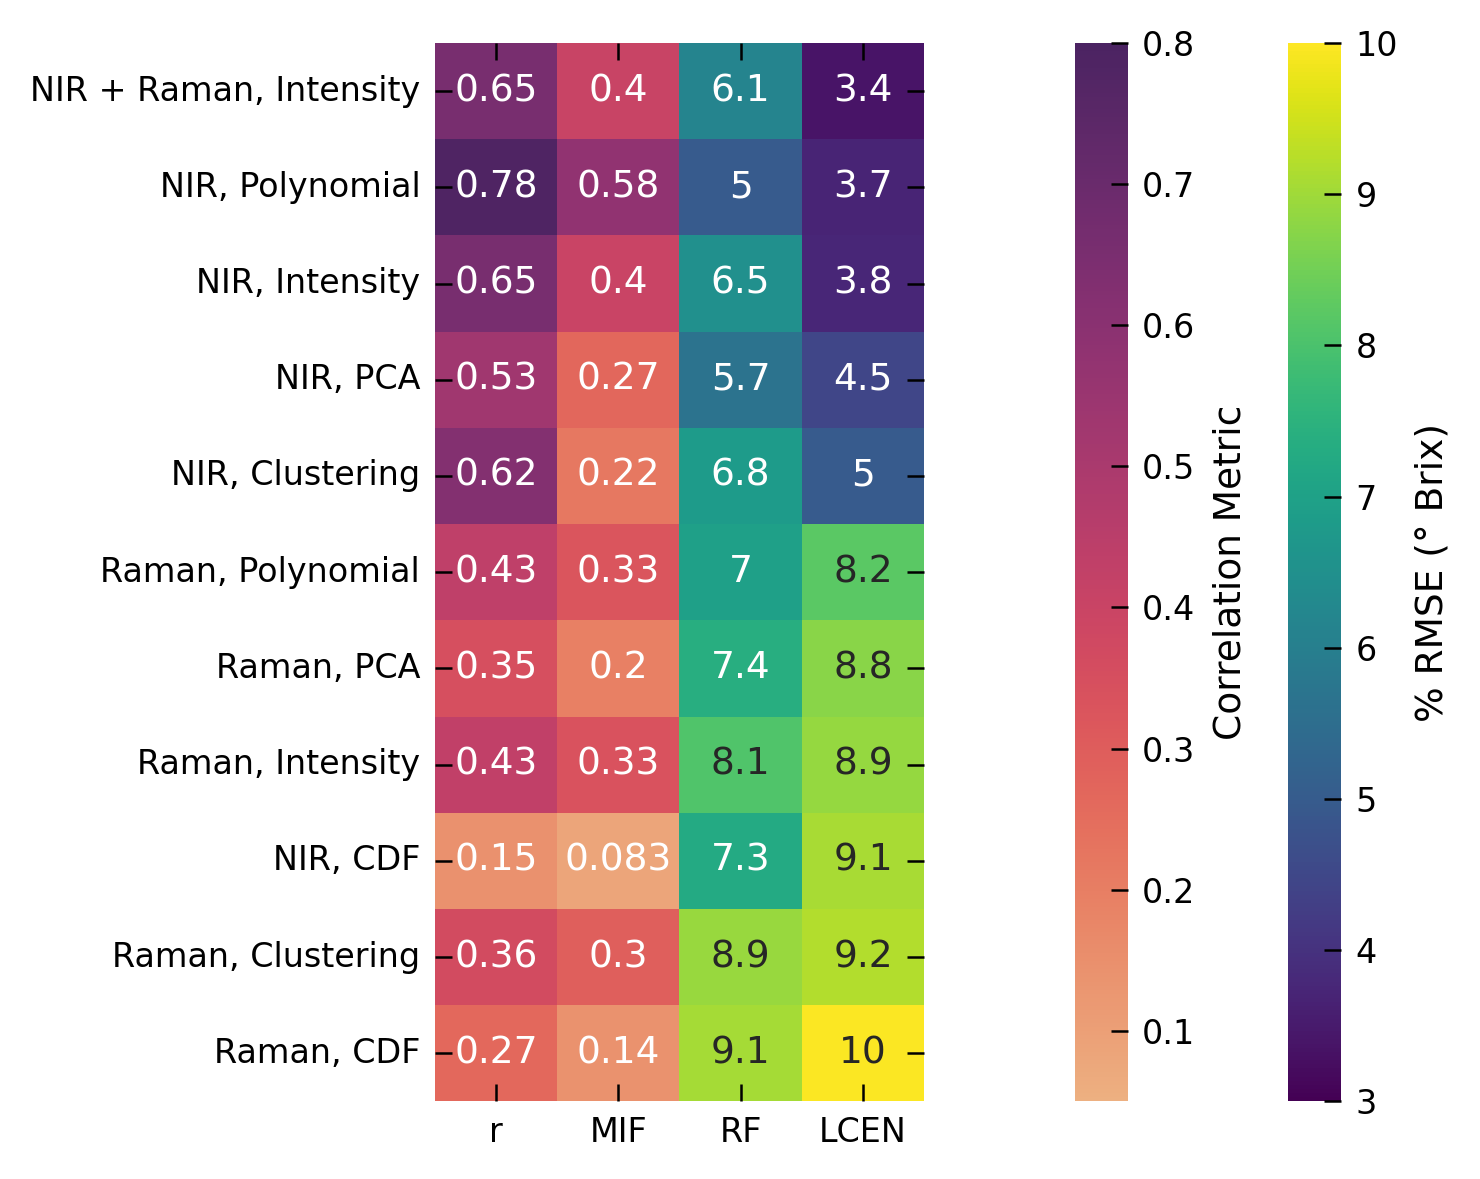

In [71]:
cmap1 = plt.get_cmap('viridis').copy()
cmap1.set_under('none')
cmap2 = plt.get_cmap('flare').copy()
cmap2.set_over('none')
f, ax1 = plt.subplots(1,1,figsize=(5,4))
ax1 = sns.heatmap(merged_err.sort_values('LCEN'), vmin=3., vmax=10,annot=True, cmap=cmap1, cbar_kws={'pad':0.1})
sns.heatmap(merged_err.sort_values('LCEN'), vmin=0.05, vmax=0.8, cmap=cmap2, ax=ax1, cbar_kws={'pad':0.2})
# ax1.set_yticklabels([PRETTY_LABELS_DICT[ind] for ind in merged_err.index])

# Add labels to colorbars for the two colorbars present
cbar1 = ax1.collections[0].colorbar
cbar2 = ax1.collections[1].colorbar
cbar1.set_label('% RMSE (° Brix)')
cbar2.set_label('Correlation Metric')

# plt.savefig('Figures/Grapes_Correlation_CENTEREDSCALED_CUTOFF.pdf')
# plt.savefig('Figures/Grapes_Correlation_CENTEREDSCALED_CUTOFF.svg')


### Plot Correlation Analysis: NIR/Raman vs. XANES

Compare the Pearson-r / MIF / % RMSE heatmap for the grape NIR + Raman
dataset side-by-side with an equivalent heatmap for the XANES + PDF dataset.

In [88]:
def plot_two_heatmaps(df, sort_by, vrange1, vrange2, ax, cm1='viridis', cm2='flare', annot_kws=None): 
    (vmin1, vmax1) = vrange1
    (vmin2, vmax2) = vrange2
    cmap1 = plt.get_cmap(cm1).copy()
    cmap1.set_under('none')
    cmap2 = plt.get_cmap(cm2).copy()
    cmap2.set_over('none')
    # f, ax1 = plt.subplots(1,1,figsize=(6,4))
    ax1 = sns.heatmap(df.sort_values(sort_by), vmin=vmin1, vmax=vmax1,annot=True, cmap=cmap1, cbar_kws={'pad':0.2},ax=ax, annot_kws=annot_kws)
    sns.heatmap(df.sort_values(sort_by), vmin=vmin2, vmax=vmax2, cmap=cmap2, ax=ax1, cbar_kws={'pad':0.2}, annot_kws=annot_kws)

    # Add labels to colorbars for the two colorbars present
    cbar1 = ax.collections[0].colorbar
    cbar2 = ax.collections[1].colorbar
    return ax, cbar1, cbar2

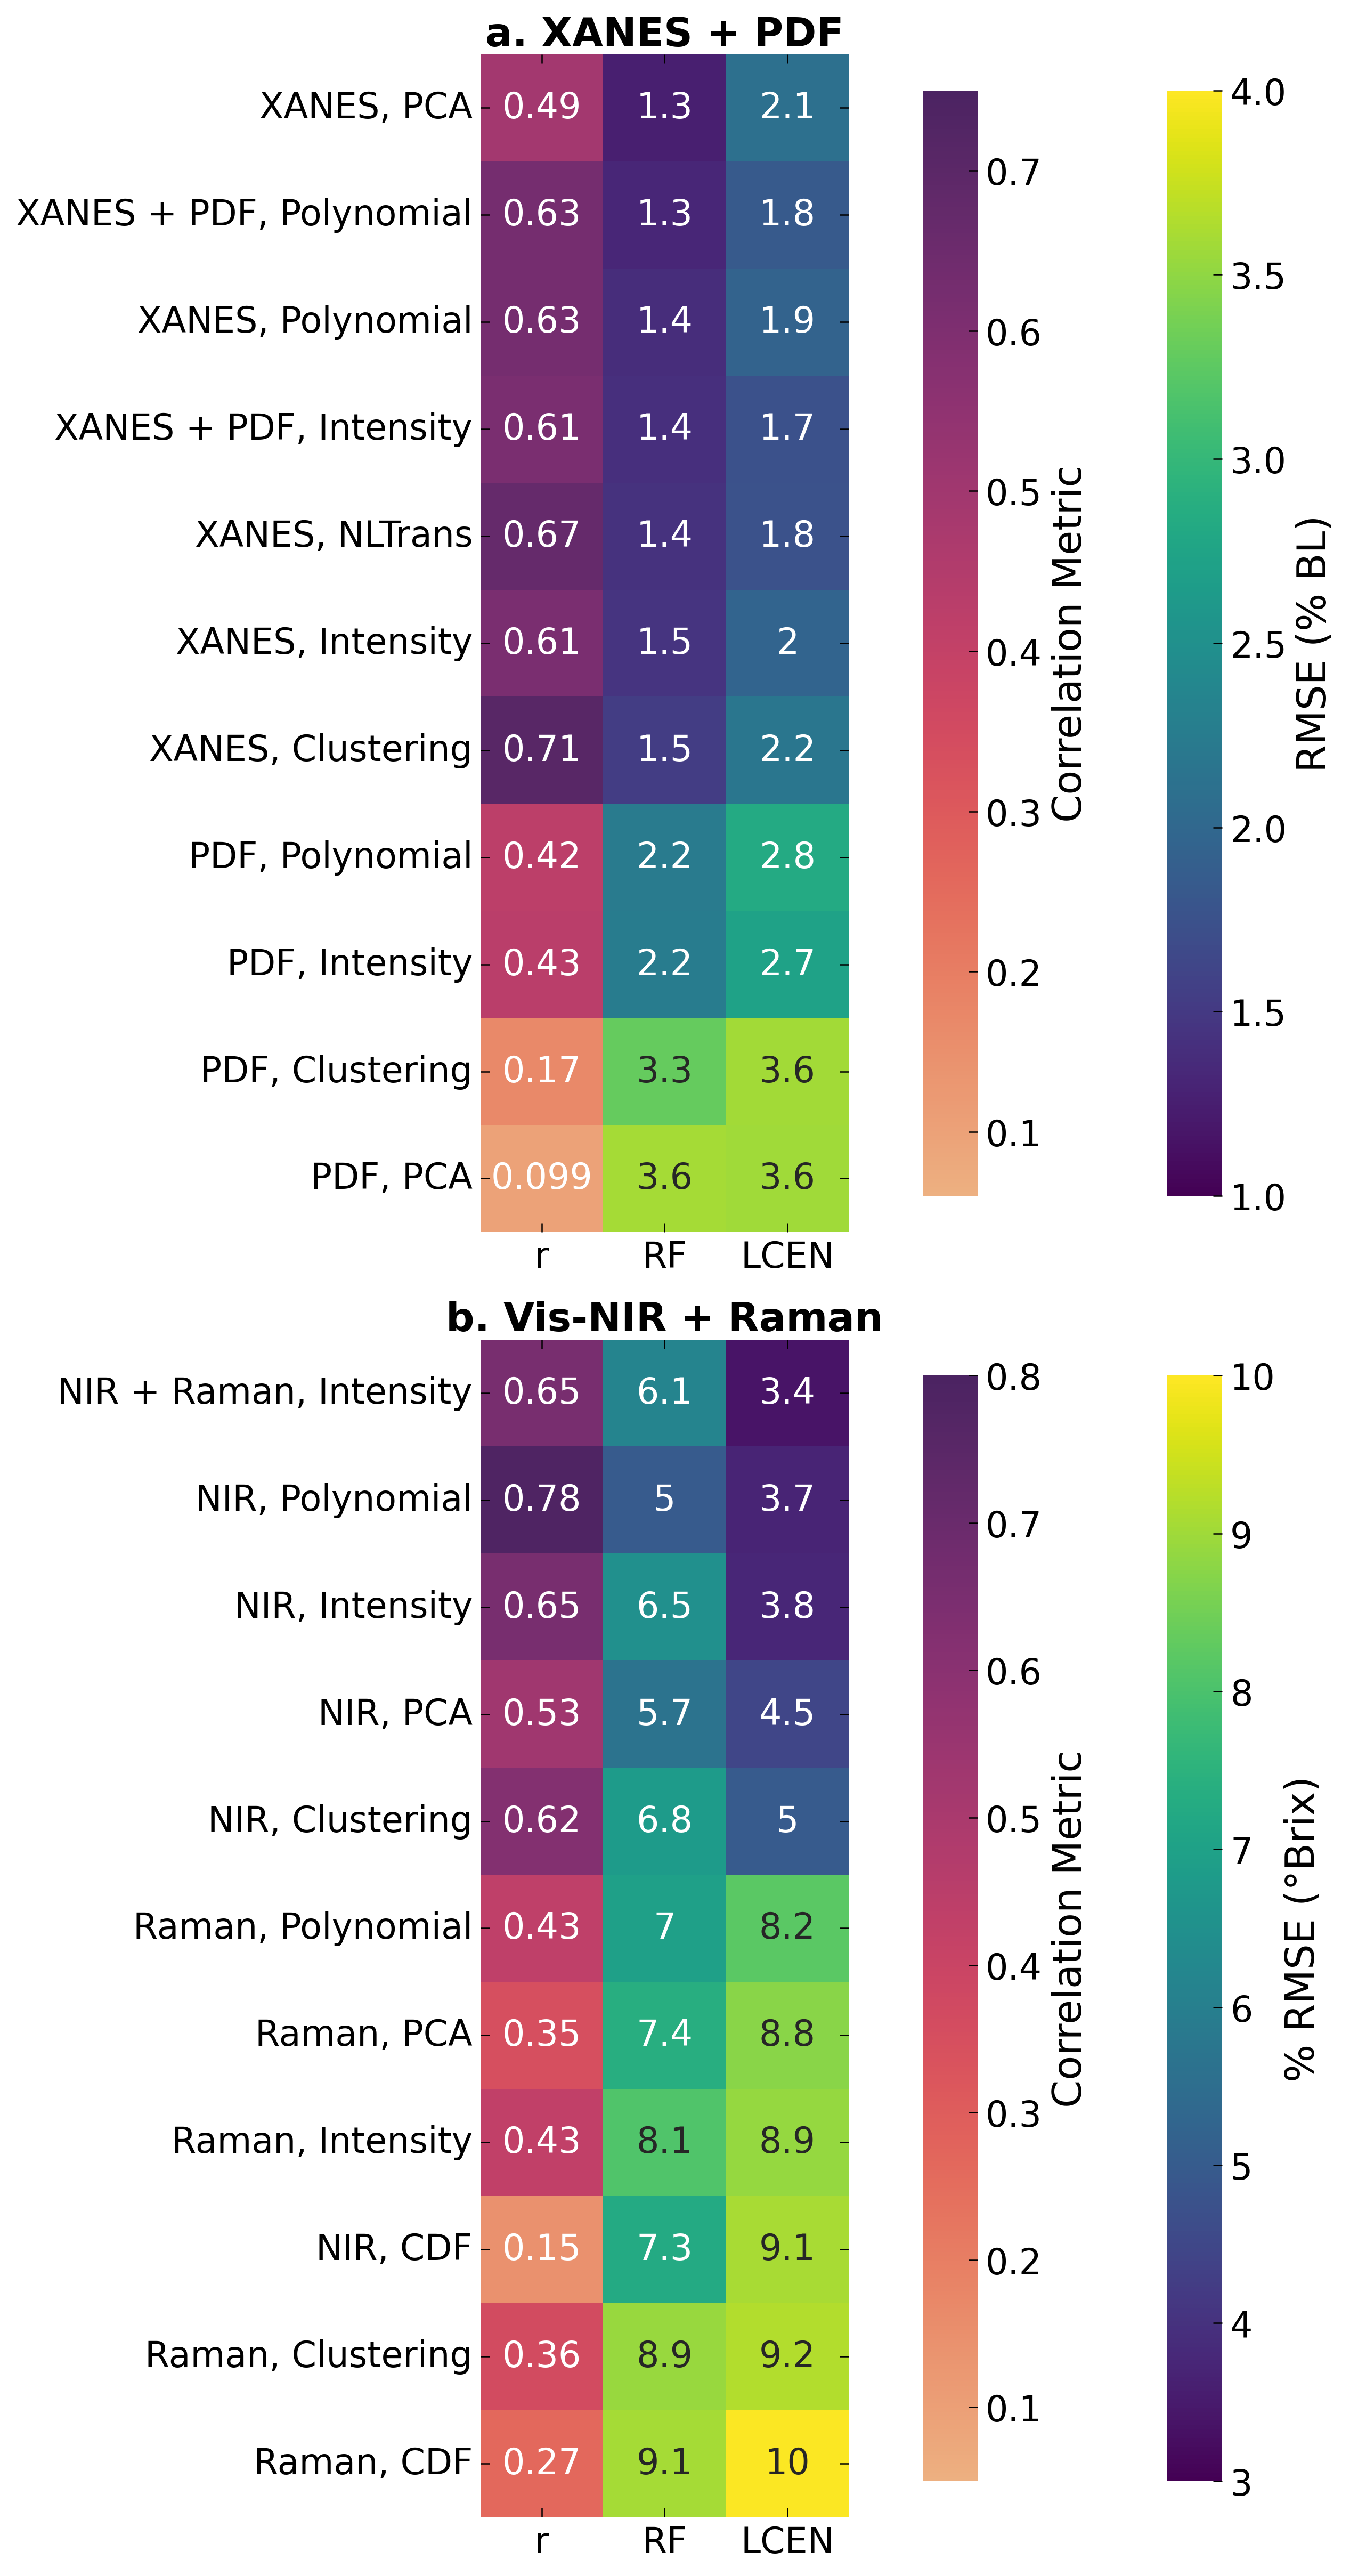

In [91]:
xanes_files = [
    'Figures/XANES_rMAX_all.csv',
    'Figures/XANES_rMAX.csv',
    'Figures/XANES_rMEAN.csv'
]

grapes_files = [
    'Figures/Grapes_rMAX_all.csv',
    'Figures/Grapes_rMAX.csv',
    'Figures/Grapes_rMEAN.csv'
]

fig, (ax2, ax1) = plt.subplots(2,1, figsize=(9,16), constrained_layout=True)

# Plot grapes_files[0]
labelsize = 18
titlesize = 20
ticksize = 16
fontsize=16
df_grapes = pd.read_csv(grapes_files[0], index_col=0)
if 'MIF' in df_grapes.columns:
    df_grapes = df_grapes[['r', 'RF', 'LCEN']]
ax_g, cb1_g, cb2_g = plot_two_heatmaps(df_grapes, sort_by='LCEN', vrange1=(3,10), vrange2=(0.05,0.8), ax=ax1, annot_kws={"fontsize":fontsize})
cb1_g.set_label('% RMSE (°Brix)')
cb2_g.set_label('Correlation Metric')

df_xanes = pd.read_csv(xanes_files[0], index_col=0)
if 'MIF' in df_xanes.columns:
    df_xanes = df_xanes[['r', 'RF', 'LCEN']]
    df_xanes = df_xanes.drop(index='XANES, CDF', errors='ignore')
ax_x, cb1_x, cb2_x = plot_two_heatmaps(df_xanes, sort_by='RF', vrange1=(1,4), vrange2=(0.06,0.75), ax = ax2, annot_kws={"fontsize":fontsize})
cb1_x.set_label('RMSE (% BL)')
cb2_x.set_label('Correlation Metric')

# Update tick label sizes, axis label sizes, and colorbar label sizes for all axes and colorbars

# Set new text and tick sizes

# ax1, ax2, ax_g, ax_x may be present depending on previous context; handle all

for ax in [ax1, ax2]:
    ax.tick_params(axis='both', which='major', labelsize=ticksize)
    ax.tick_params(axis='both', which='minor', labelsize=ticksize)
    ax.xaxis.label.set_size(labelsize)
    ax.yaxis.label.set_size(labelsize)
    if ax.get_title():
        ax.title.set_size(titlesize)

# ax_g, ax_x are both valid axis handles from plot_two_heatmaps
for ax in [ax_g, ax_x]:
    ax.tick_params(axis='both', which='major', labelsize=ticksize)
    ax.tick_params(axis='both', which='minor', labelsize=ticksize)
    ax.xaxis.label.set_size(labelsize)
    ax.yaxis.label.set_size(labelsize)
    if ax.get_title():
        ax.title.set_size(titlesize)

# Set colorbar label sizes and tick sizes
for cb in [cb1_g, cb2_g, cb1_x, cb2_x]:
    cb.ax.tick_params(labelsize=ticksize)
    cb.set_label(cb.ax.get_ylabel(), fontsize=labelsize)

# Fix for the subfigure labels (the letters)
labels = ['a. XANES + PDF', 'b. Vis-NIR + Raman']
for i,ax in enumerate([ax2, ax1]): 
    ax.set_title(labels[i], 
            ha='center', va='center', fontsize=18, fontweight='bold',transform=ax.transAxes, pad=5)

# plt.tight_layout()
# plt.show()
plt.savefig('Figures/Correlation_Figure6.pdf')
plt.savefig('Figures/Correlation_Figure6.svg')

ValueError: The number of FixedLocator locations (4), usually from a call to set_ticks, does not match the number of labels (3).

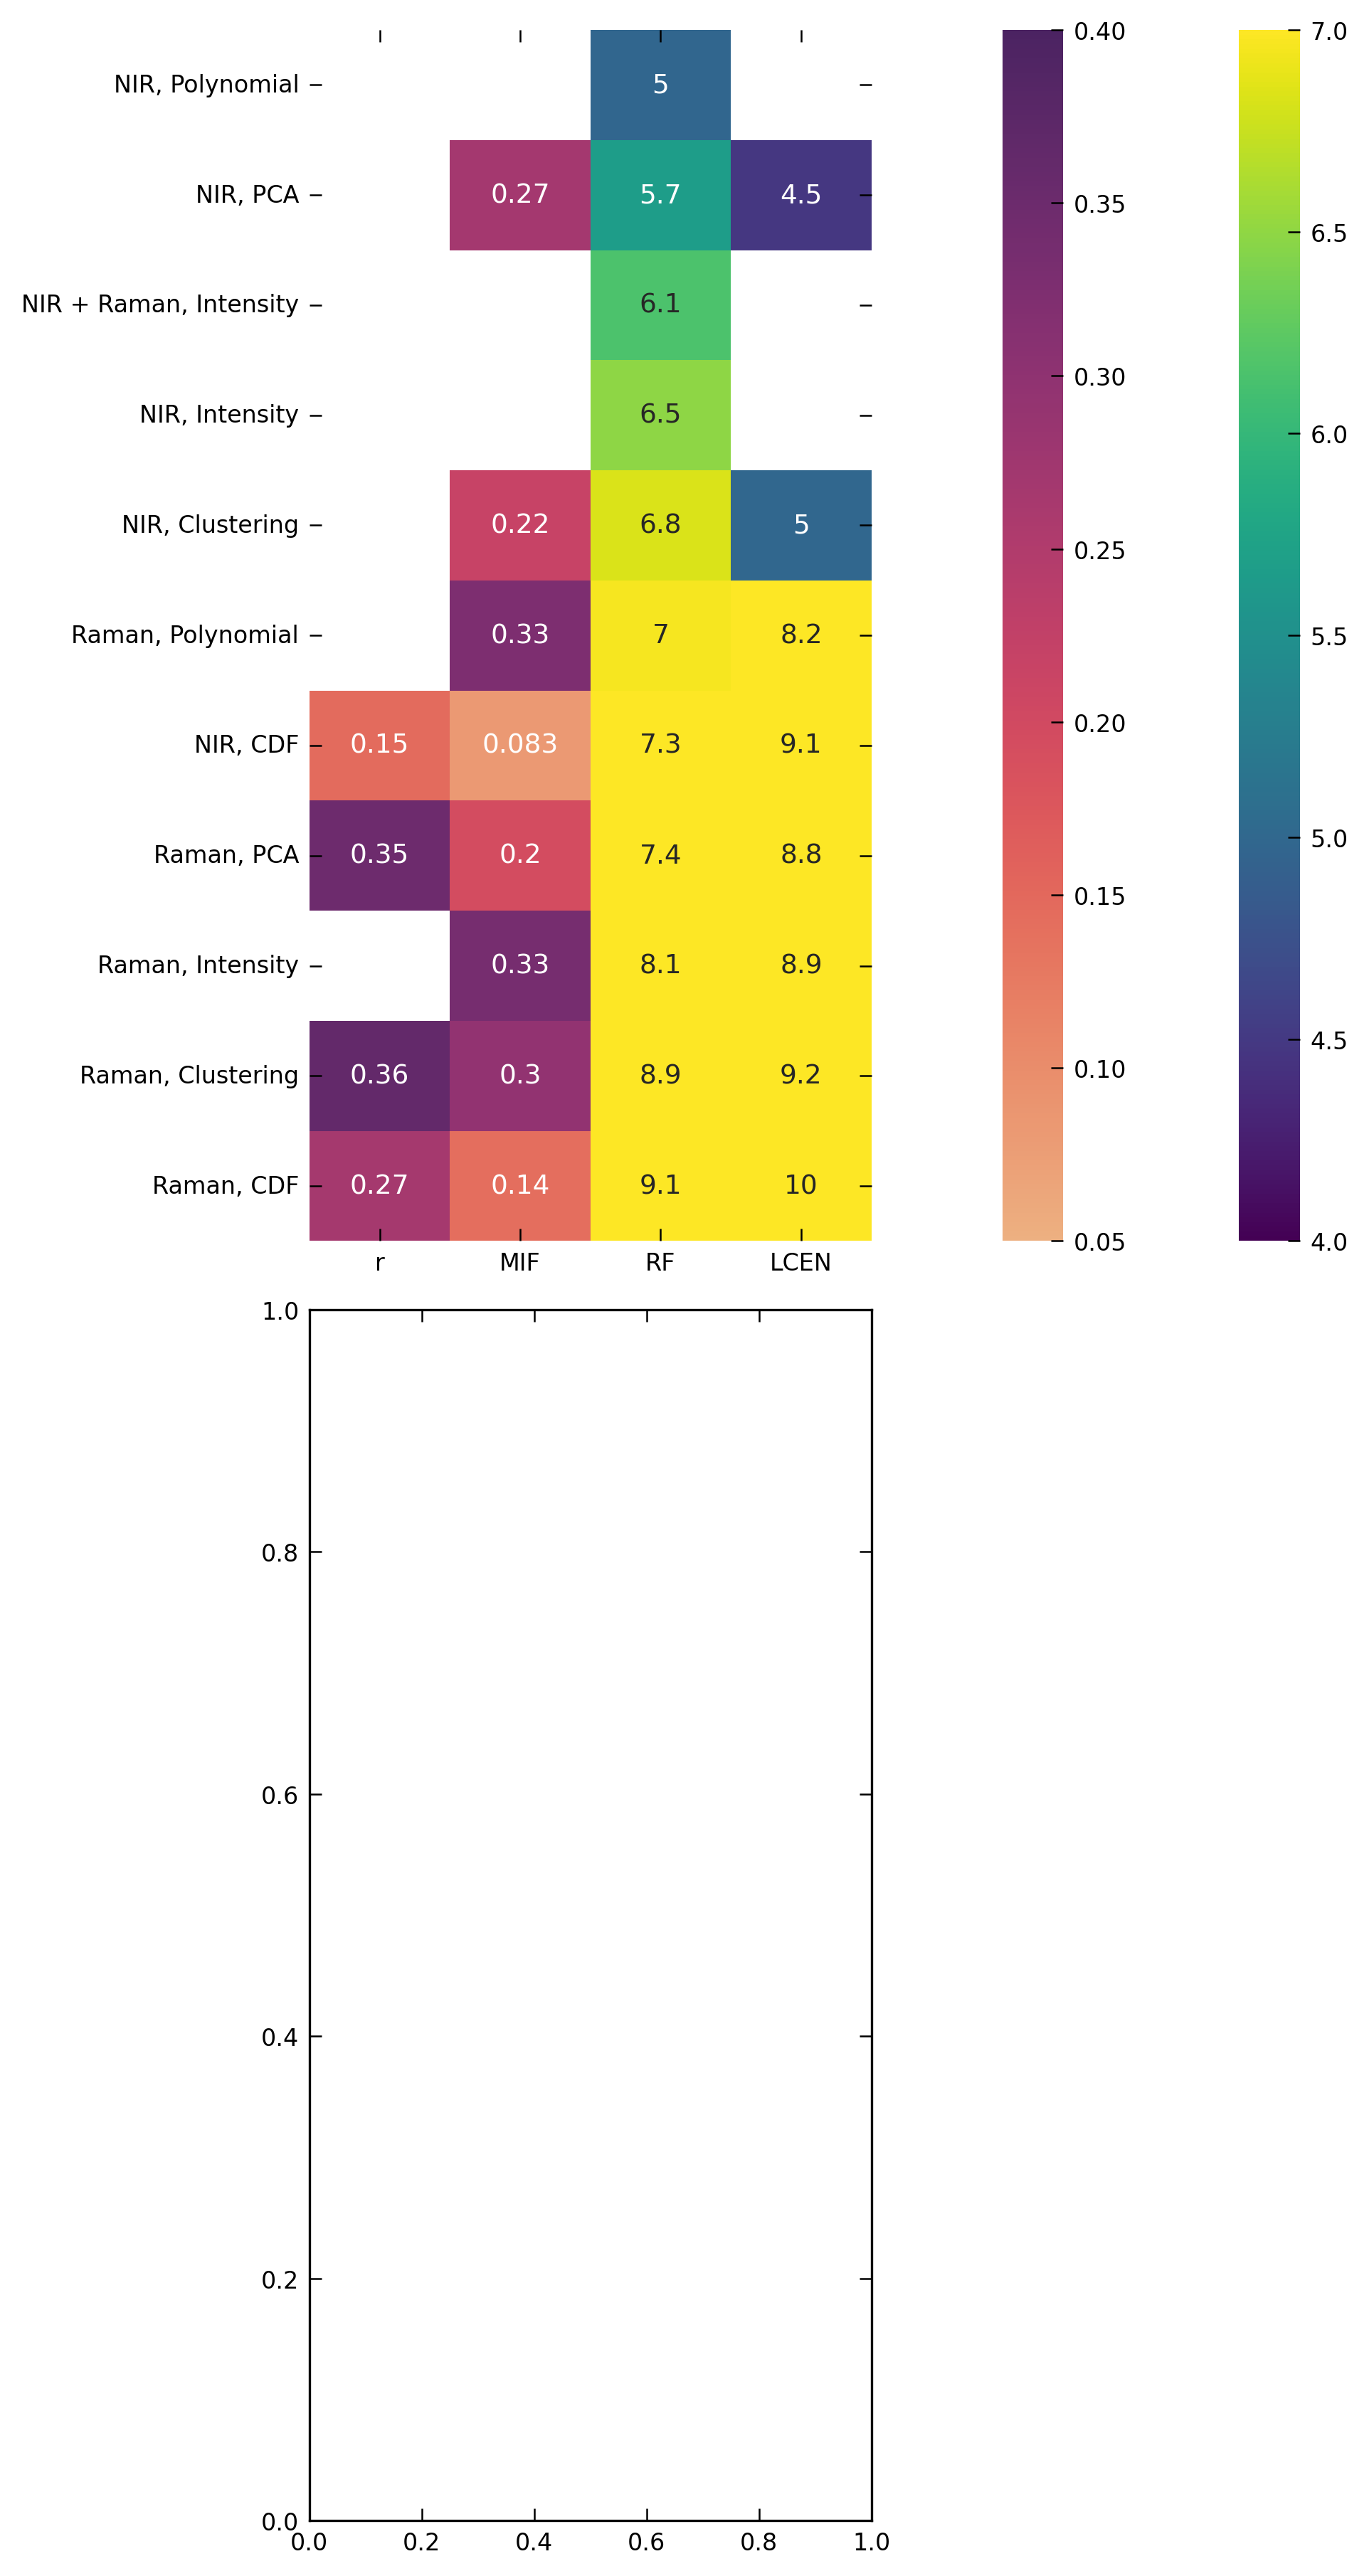

In [82]:
xanes_merged = pd.read_csv('Figures/XANES_corr.csv', index_col=0)
fontsize=15
ticksize=12
f, (ax1, ax2) = plt.subplots(2,1,figsize=(7,12), constrained_layout=True)

cmap1 = plt.get_cmap('viridis').copy()
cmap1.set_under('none')
cmap2 = plt.get_cmap('flare').copy()
cmap2.set_over('none')
sns.heatmap(merged_err.sort_values('RF'), vmin=4, vmax=7,annot=True, ax=ax1, cmap=cmap1, cbar_kws={'pad':0.2})
sns.heatmap(merged_err.sort_values('RF'), vmin=0.05, vmax=0.4, cmap=cmap2, ax=ax1, cbar_kws={'pad':0.2})
# ax1.set_yticklabels([PRETTY_LABELS_DICT[ind] for ind in merged_err.index])
ax1.set_xticklabels(['r', 'MIF', 'LCEN Metric'], rotation=15, ha='center')

# Add labels to colorbars for the two colorbars present
cbar1 = ax1.collections[0].colorbar
cbar2 = ax1.collections[1].colorbar
cbar1.set_label('% RMSE (° Brix)', size=fontsize)
cbar2.set_label('Correlation Metric', size=fontsize)
cbar1.ax.tick_params(labelsize=ticksize)
cbar2.ax.tick_params(labelsize=ticksize)

cmap1 = plt.get_cmap('viridis').copy()
cmap1.set_under('none')
cmap2 = plt.get_cmap('flare').copy()
cmap2.set_over('none')
ax2 = sns.heatmap(xanes_merged.sort_values('LCEN'), vmin=1, vmax=4,annot=True, cmap=cmap1, cbar_kws={'pad':0.2})
sns.heatmap(xanes_merged.sort_values('LCEN'), vmin=0.05, vmax=0.4, cmap=cmap2, ax=ax2, cbar_kws={'pad':0.2})
ax2.set_xticklabels(['r', 'MIF', 'RF Metric'], rotation=15, ha='center')
# Add labels to colorbars for the two colorbars present
cbar1 = ax2.collections[0].colorbar
cbar2 = ax2.collections[1].colorbar
cbar1.set_label('RMSE (% BL)', size=fontsize)
cbar2.set_label('Correlation Metric', size=fontsize)
cbar1.ax.tick_params(labelsize=ticksize)
cbar2.ax.tick_params(labelsize=ticksize)

titles = [r'$\bf{a.}$ XANES + PDF', r'$\bf{b.}$ NIR + Raman']
for i,ax in enumerate([ax1, ax2]):
    for item in (ax.get_xticklabels() + ax.get_yticklabels()):
        item.set_fontsize(fontsize)
    ax.tick_params(axis='both', which='major', labelsize=ticksize)
    ax.tick_params(axis='both', which='minor', labelsize=ticksize)
    ax.xaxis.label.set_size(fontsize)
    ax.yaxis.label.set_size(fontsize)
    ax.title.set_size(fontsize)
    for t in ax.texts:
        t.set_fontsize(12)
    ax.set_title(f'{titles[i]}', size=fontsize)

plt.savefig('Figures/Fig6_Corr.pdf')
plt.savefig('Figures/Fig6_Corr.svg')

### Visualize Top Two PCA Components for °Brix Regression

Scatter the two PCA components most important to RF and LCEN,
coloured by °Brix, to visualise how well the data separates.

Text(0.5, 1.0, 'NIR, PCA, LCEN')

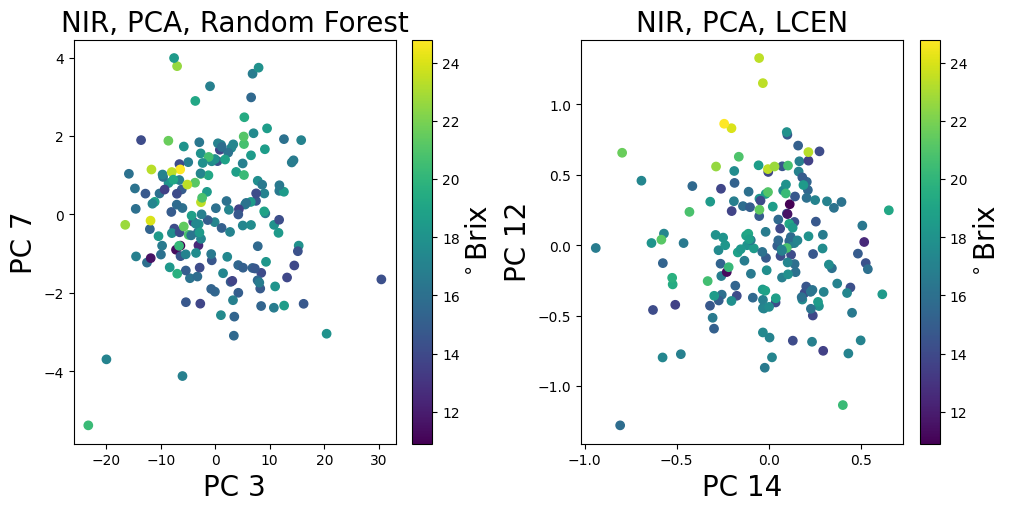

In [ ]:
f, (ax1, ax2) = plt.subplots(1,2,figsize=(10,5), constrained_layout=True)
top_pca_rf = ss_f.nir_pca_br_RandomForestRegressor['selected_features'][:2]
top_pca = ss_f.nir_pca_br_LCEN['selected_features'][:2]

scatter1 = ax1.scatter(ss_f.nir_pca[:,top_pca_rf[0]], ss_f.nir_pca[:,top_pca_rf[1]], c=ss_f.br, cmap='viridis')
scatter2 = ax2.scatter(ss_f.nir_pca[:,top_pca[0]], ss_f.nir_pca[:,top_pca[1]], c=ss_f.br, cmap='viridis')

cb1 = plt.colorbar(scatter1)
cb2 = plt.colorbar(scatter2)

cb1.set_label(r'$^\circ$Brix', fontsize=20)
cb2.set_label(r'$^\circ$Brix', fontsize=20)

ax1.set_xlabel(f'PC {top_pca_rf[0]+1}', fontsize=20)
ax1.set_ylabel(f'PC {top_pca_rf[1]+1}', fontsize=20)
ax2.set_xlabel(f'PC {top_pca[0]+1}', fontsize=20)
ax2.set_ylabel(f'PC {top_pca[1]+1}', fontsize=20)

ax1.set_title('NIR, PCA, Random Forest', fontsize=20)
ax2.set_title('NIR, PCA, LCEN', fontsize=20)

#### Pretty-Label Map for Plotting

Define a `labels` list of human-readable feature names in the
same order as `ss_f.generated_features`, used by Figure 4.

### Main Text Figure 4

Multi-panel figure: (a) % RMSE heatmap for all feature/model combinations;
(b–c) raw NIR spectra with top-10 selected features highlighted for RF and LCEN,
comparing pointwise-intensity vs. polynomial-fit feature representations.

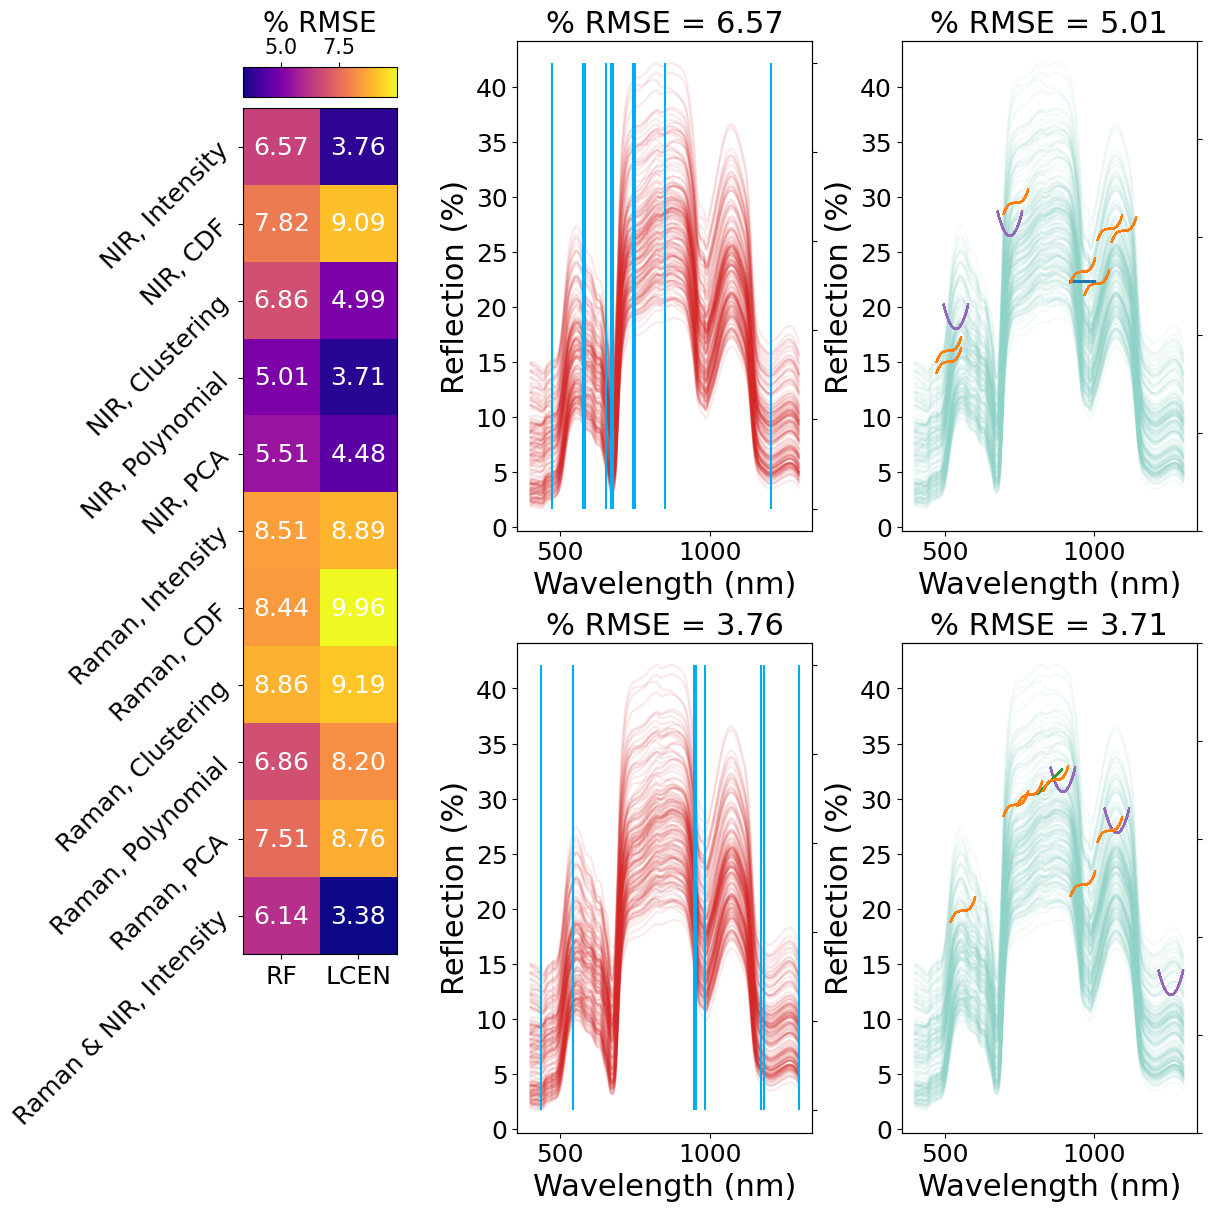

In [ ]:
import matplotlib.gridspec as gridspec
fontsize = 22
ticklabelsize = 18


results_df = copy.copy(pd.DataFrame(ss_f.best_fits).T)

# Setting up the figure 
fig = plt.figure(figsize=(12, 12), constrained_layout=True)
outer_gs = gridspec.GridSpec(2,3, figure=fig, width_ratios=[1,2.5,2.5], height_ratios=[1, 1], hspace=0.5, wspace=0.2)
# First row: 3 subplots
ax1 = fig.add_subplot(outer_gs[:,0])
inner_top = gridspec.GridSpecFromSubplotSpec(2,1, subplot_spec=outer_gs[:,1], wspace=0.3)
ax4 = fig.add_subplot(inner_top[0])
ax2 = fig.add_subplot(inner_top[1])

inner_bottom = gridspec.GridSpecFromSubplotSpec(2,1, subplot_spec=outer_gs[:,2], wspace=0.3)
ax5 = fig.add_subplot(inner_bottom[0])
ax3 = fig.add_subplot(inner_bottom[1])

#Twin x axis for plotting the selected features 
ax2_twin = ax2.twinx()
ax3_twin = ax3.twinx()
ax4_twin = ax4.twinx()
ax5_twin = ax5.twinx()


prmse_df = ((results_df.T) / ss_f.br.max()) * 100  # percent RMSE
prmse_df = prmse_df[['RandomForestRegressor', 'LCEN']]
im = ax1.imshow(prmse_df, cmap='plasma')
ax1.set_yticks(np.arange(len(labels)));
ax1.set_yticklabels(labels, rotation=45, ha='right', size=18);
ax1.set_xticks([0, 1])
ax1.set_xticklabels(['RF', 'LCEN'], size=18)
cb1 = fig.colorbar(im, ax=ax1, location='top', aspect=5, pad=0.01)
cb1.ax.tick_params(labelsize=15)  # Tick label font size
cb1.set_label('% RMSE', fontsize=20)

for (i, j), val in np.ndenumerate(prmse_df):
    ax1.text(j, i, f'{val:.2f}', ha='center', va='center', color='white',size=ticklabelsize)

spec = 'nir'

for mn, axes in zip(['RandomForestRegressor', 'LCEN'], [(ax4, ax5, ax4_twin), (ax2, ax3, ax2_twin)]):
    ax_i, ax_ii, ax_twin = axes
    rmse = pd.DataFrame(ss_f.best_fits).T[['nir_pointwise_features_br', 'nir_polynomial_featuresall_br']].loc[mn].values
    subplot_titles=['', '']
    subplot_titles = [title + f'% RMSE = {round(100 * r / np.max(ss_f.br), 2)}' for title, r in zip(subplot_titles, (rmse))]
    ax_i.set_title(subplot_titles[0], fontsize=fontsize)
    ax_ii.set_title(subplot_titles[1], fontsize=fontsize)
    # for spectrum in ss_f.nir_pointwise_features: 
    for spectrum in XSF_br: 
        spectrum = spectrum[selected_wls]
        ax_i.plot(ss_f.nir_xaxis, spectrum, color='#d62728', alpha=0.1)
        ax_ii.plot(ss_f.nir_xaxis, spectrum, color=plt.cm.Set3(np.arange(10))[0], alpha=0.1)

    model = getattr(ss_f, f'{spec}_pointwise_features_br_{mn}')
    selected_features = model['selected_features'][:10]
    selected_vals = model['selected_vals'][:10]
    for i in selected_features:
        ax_twin.vlines(ss_f.nir_xaxis[i], 0, 1, color='#00ADF2', alpha=1)
    
plot_spectral_features_matplotlib(ss_f.nir_xaxis, XSF_br[0,selected_wls], ss_f.nir_polynomial_featuresall_br_RandomForestRegressor['selected_features'][:10], ax=ax5,zoom=0.05, plot_raw=False)
plot_spectral_features_matplotlib(ss_f.nir_xaxis, XSF_br[0,selected_wls], ss_f.nir_polynomial_featuresall_br_LCEN['selected_features'][:10], ax=ax3,zoom=0.05, plot_raw=False)


for ax in [ax2, ax3, ax4, ax5]:
    ax.set_xlabel('Wavelength (nm)',fontsize=fontsize)
    ax.set_ylabel('Reflection (%)',fontsize=fontsize)
    ax.tick_params(axis='both', labelsize=ticklabelsize)
    ax.xaxis.label.set_size(fontsize)
    ax.yaxis.label.set_size(fontsize)

for ax in [ax2_twin, ax3_twin, ax4_twin, ax5_twin]:
    ax.set_yticklabels([]);


plt.savefig(f"../JOSS/Figures/Fig4_121525.svg")
plt.savefig(f"../JOSS/Figures/Fig4_121525.pdf")
# ax2.vlines(850, 0, 40, color='k', label='850nm')
# ax2.vlines(970, 0, 40, color='r', label='970nm')
# ax2.vlines(1200, 0, 40, color='g', label='1150nm')
# ax2.vlines(840, 0, 40, color='k', label='840')
# ax2.vlines(738, 0, 40, color='b', label='738')
# ax2.vlines(1100, 0, 40, color='b', label='1100')

# ax2.legend()
plt.savefig(f"Figures/Fig4_022526_annot.svg")
plt.savefig(f"Figures/Fig4_022526_annot.pdf")


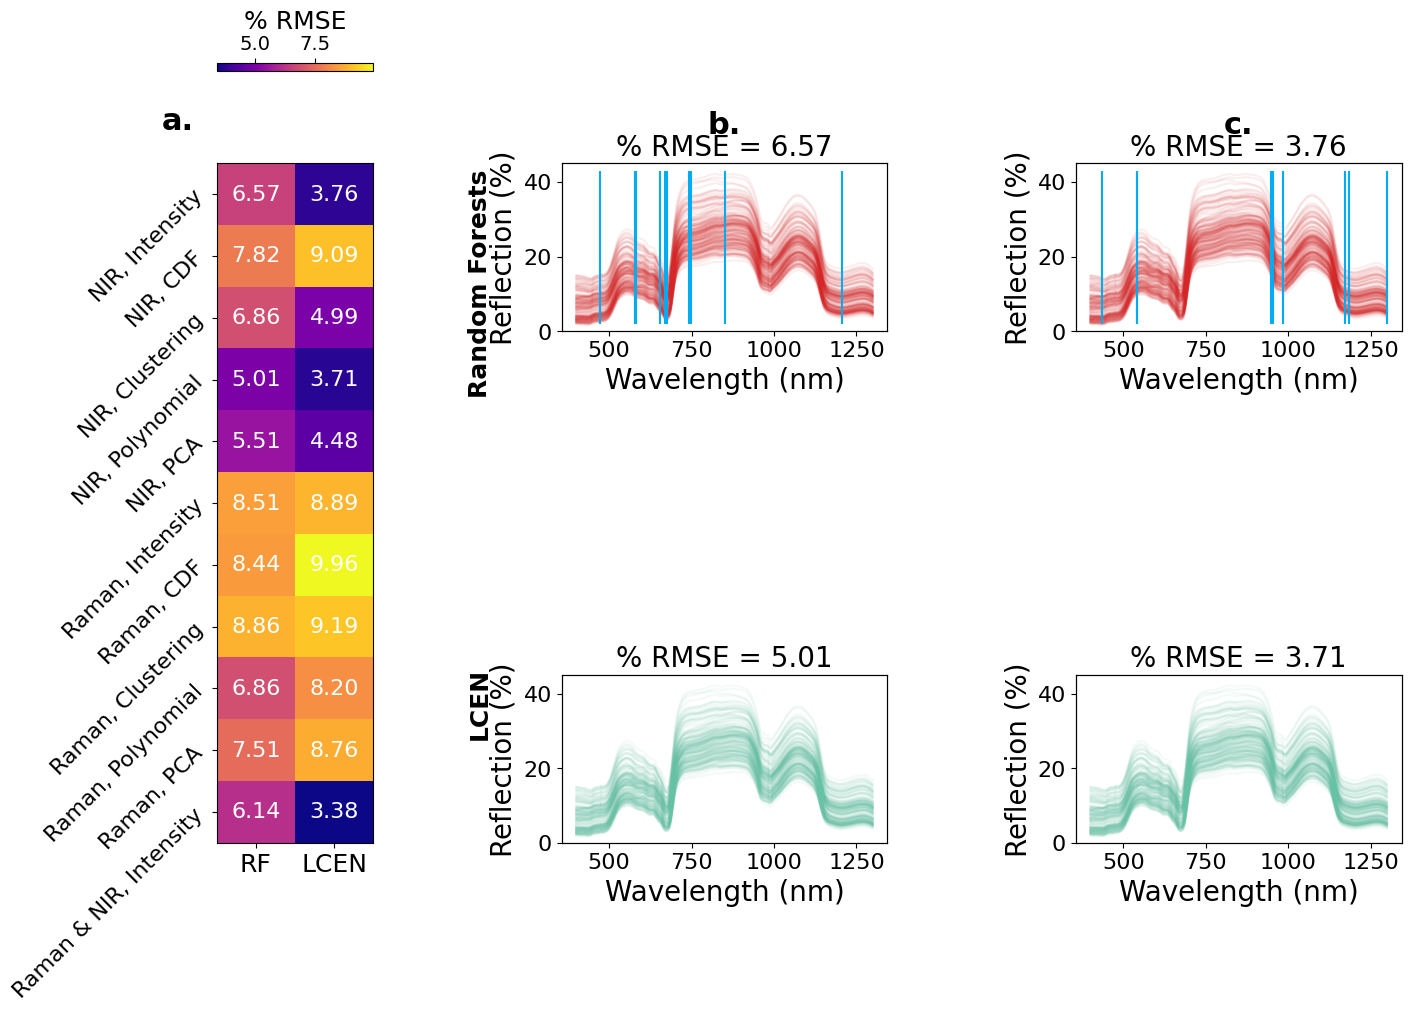

In [ ]:
fontsize = 20
ticklabelsize = 16

results_df = copy.copy(pd.DataFrame(ss_f.best_fits).T)

# --------------------------------------------------
# FIGURE LAYOUT
# --------------------------------------------------
fig = plt.figure(figsize=(14, 10), constrained_layout=True)

outer = gridspec.GridSpec(
    2, 3,
    figure=fig,
    width_ratios=[1.2, 2.5, 2.5],
    height_ratios=[1, 1],
    wspace=0.25,
    hspace=0.25
)

# Heatmap spans full left column
ax_heat = fig.add_subplot(outer[:, 0])

# RF column
ax_rf_i   = fig.add_subplot(outer[0, 1])
ax_rf_ii  = fig.add_subplot(outer[1, 1])

# LCEN column
ax_lcen_i  = fig.add_subplot(outer[0, 2])
ax_lcen_ii = fig.add_subplot(outer[1, 2])

# Twin axes for feature lines
ax_rf_i_twin   = ax_rf_i.twinx()
ax_rf_ii_twin  = ax_rf_ii.twinx()
ax_lcen_i_twin = ax_lcen_i.twinx()
ax_lcen_ii_twin= ax_lcen_ii.twinx()

# --------------------------------------------------
# HEATMAP
# --------------------------------------------------
prmse_df = ((results_df.T) / ss_f.br.max()) * 100
prmse_df = prmse_df[['RandomForestRegressor', 'LCEN']]

im = ax_heat.imshow(prmse_df, cmap='plasma', aspect='auto')

ax_heat.set_xticks([0, 1])
ax_heat.set_xticklabels(['RF', 'LCEN'], fontsize=18)

ax_heat.set_yticks(np.arange(len(labels)))
ax_heat.set_yticklabels(labels, rotation=45, ha='right', fontsize=16)

# Annotate values
for (i, j), val in np.ndenumerate(prmse_df.values):
    ax_heat.text(j, i, f"{val:.2f}",
                 ha='center', va='center',
                 color='white', fontsize=16)

# Horizontal colorbar on TOP
cb = fig.colorbar(
    im,
    ax=ax_heat,
    orientation="horizontal",
    location="top",
    pad=0.05,
    fraction=0.08
)
cb.set_label('% RMSE', fontsize=18)
cb.ax.tick_params(labelsize=14)

# Panel label
ax_heat.text(-0.35, 1.05, "a.", transform=ax_heat.transAxes,
             fontsize=22, fontweight='bold')

# --------------------------------------------------
# SPECTRA PLOTS
# --------------------------------------------------

def plot_block(model_name, ax_i, ax_ii, ax_i_twin, ax_ii_twin, col_title):
    spec = 'nir'
    rmse = pd.DataFrame(ss_f.best_fits).T[
        ['nir_pointwise_features_br', 'nir_polynomial_featuresall_br']
    ].loc[model_name].values

    rmse_percent = [round(100 * r / np.max(ss_f.br), 2) for r in rmse]

    ax_i.set_title(f"% RMSE = {rmse_percent[0]}", fontsize=fontsize)
    ax_ii.set_title(f"% RMSE = {rmse_percent[1]}", fontsize=fontsize)

    # Plot spectra
    for spectrum in XSF_br:
        spectrum = spectrum[selected_wls]
        ax_i.plot(ss_f.nir_xaxis, spectrum,
                  color='#d62728', alpha=0.08)
        ax_ii.plot(ss_f.nir_xaxis, spectrum,
                   color='#66c2a5', alpha=0.08)

    # Selected features (vertical lines)
    model = getattr(ss_f, f'{spec}_pointwise_features_br_{model_name}')
    selected_features = model['selected_features'][:10]

    for idx in selected_features:
        ax_i_twin.vlines(
            ss_f.nir_xaxis[idx], 0, 1,
            color='#00ADF2', linewidth=1.5
        )

    # Clean twin axis
    ax_i_twin.set_yticks([])
    ax_ii_twin.set_yticks([])

    # Axis formatting
    for ax in [ax_i, ax_ii]:
        ax.set_xlabel('Wavelength (nm)', fontsize=fontsize)
        ax.set_ylabel('Reflection (%)', fontsize=fontsize)
        ax.tick_params(axis='both', labelsize=ticklabelsize)
        ax.set_ylim(0, 45)

    # Column title above block
    ax_i.text(
        0.5, 1.18,
        col_title,
        transform=ax_i.transAxes,
        ha='center',
        fontsize=22,
        fontweight='bold'
    )


# RF block
plot_block(
    "RandomForestRegressor",
    ax_rf_i, ax_rf_ii,
    ax_rf_i_twin, ax_rf_ii_twin,
    "b."
)

# LCEN block
plot_block(
    "LCEN",
    ax_lcen_i, ax_lcen_ii,
    ax_lcen_i_twin, ax_lcen_ii_twin,
    "c."
)

# --------------------------------------------------
# BIG VERTICAL ROW LABELS
# --------------------------------------------------
fig.text(0.33, 0.72, "Random Forests",
         rotation=90,
         fontsize=18,
         fontweight='bold',
         va='center')

fig.text(0.33, 0.30, "LCEN",
         rotation=90,
         fontsize=18,
         fontweight='bold',
         va='center')

# --------------------------------------------------
# SAVE
# --------------------------------------------------
plt.savefig("Figures/Fig4_updated.svg")
plt.savefig("Figures/Fig4_updated.pdf")
plt.show()

In [ ]:
ss_f.nir_polynomial_featuresall_br_LCEN['model_params']
ss_f.nir_pointwise_features_br_LCEN['model_params']

# ss_f.nir_polynomial_featuresall_br_RandomForestRegressor['P'][0].best_estimator_.feature_importances_
# ss_f.nir_pointwise_features_br_RandomForestRegressor['P'][0].best_estimator_.feature_importances_

AttributeError: 'RandomForestRegressor' object has no attribute 'coef_'

30


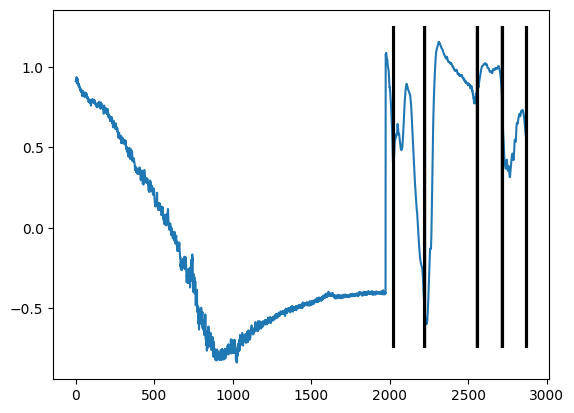

In [ ]:
model = ss_f.rm_nir_pointwise_features_br_LCEN
selected_vals, selected_feats = LCEN_selected_features(model, 31)
# selected_vals = model['selected_vals']
# selected_feats = model['selected_features']
spec  = ss_f.rm_nir_pointwise_features[10]
feature_x = np.arange(len(spec))
print(len(selected_feats))
plt.plot(feature_x, spec)
for feat in selected_feats: 
    plt.vlines(feat, -0.75, 1.25, color='k')

### Best LCEN Hyperparameters (Polynomial Features)

In [ ]:
ss_f.nir_polynomial_featuresall_br_LCEN['model_hyper']

{'degree': 1,
 'l1_ratio': 0.1,
 'alpha': 0.00707945784384138,
 'lag': 0,
 'cutoff': 5e-05,
 'trans_type': 'poly'}

### Number of Features Selected by Each LCEN Model

LCEN automatically zeroes out uninformative features; inspect how many
survive the cutoff threshold for the pointwise and polynomial schemes.

In [ ]:
print('poly features:',len(ss_f.nir_polynomial_featuresall_br_LCEN['model_params']))
print('num poly features:',len(ss_f.nir_polynomial_featuresall[0]))
print('pointwise features:',len(ss_f.nir_pointwise_features_br_LCEN['model_params']))
print('num pointwise features:',len(ss_f.nir_xaxis))

poly features: 33
num poly features: 157
pointwise features: 86
num pointwise features: 899


In [ ]:
all_selected = [int(x.replace('x', '')) for x in  np.array(ss_f.nir_pointwise_features_br_LCEN['model_params'])[1:,0]]
all_vals = [float(x) for x in  np.array(ss_f.nir_pointwise_features_br_LCEN['model_params'])[1:,1]]

(CVXPY) Feb 25 12:35:58 AM: Solver SCS succeeds
(CVXPY) Feb 25 12:35:59 AM: Solver SCS succeeds
(CVXPY) Feb 25 12:36:03 AM: Solver SCS succeeds
(CVXPY) Feb 25 12:36:16 AM: Solver SCS succeeds
(CVXPY) Feb 25 12:36:35 AM: Solver SCS succeeds
(CVXPY) Feb 25 12:36:39 AM: Solver SCS succeeds
(CVXPY) Feb 25 12:36:40 AM: Solver SCS succeeds
(CVXPY) Feb 25 12:36:40 AM: Solver SCS succeeds


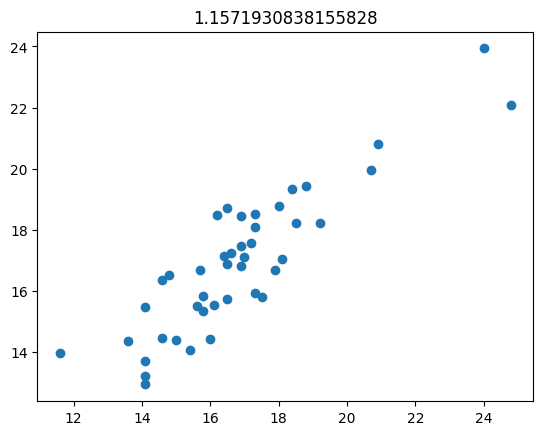

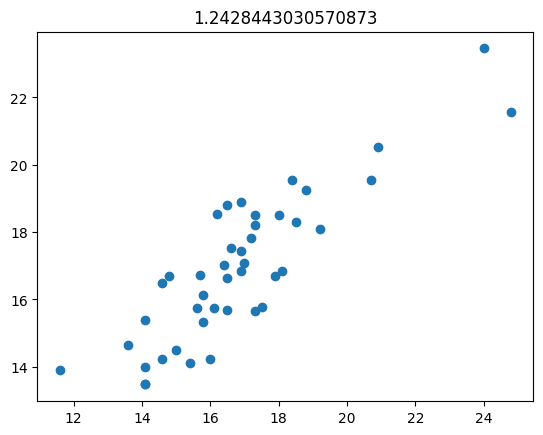

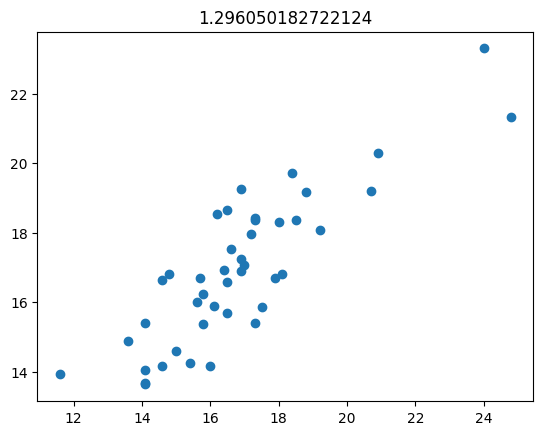

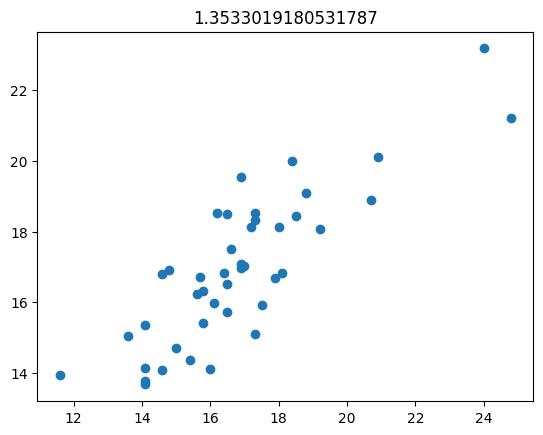

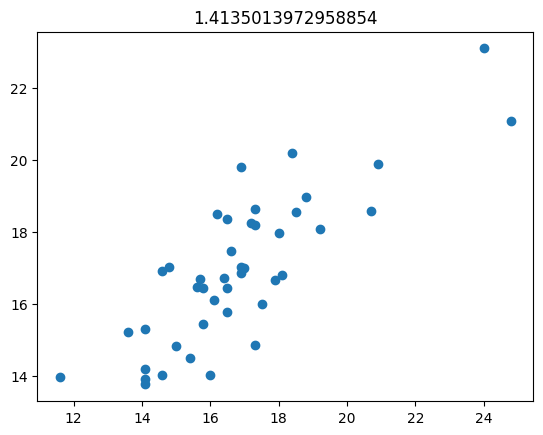

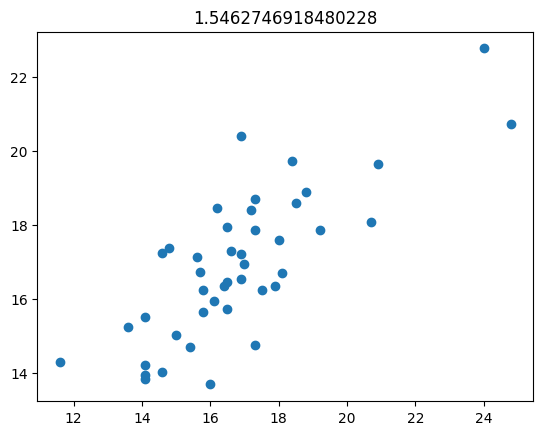

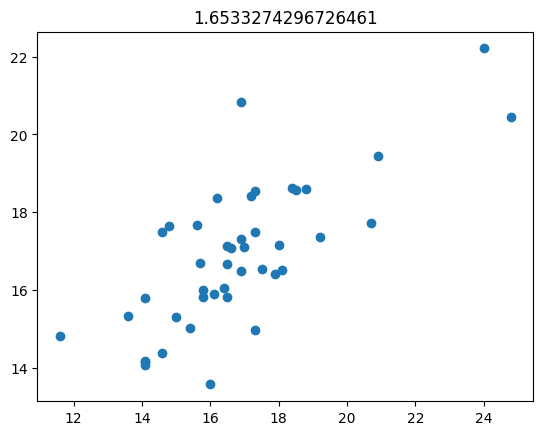

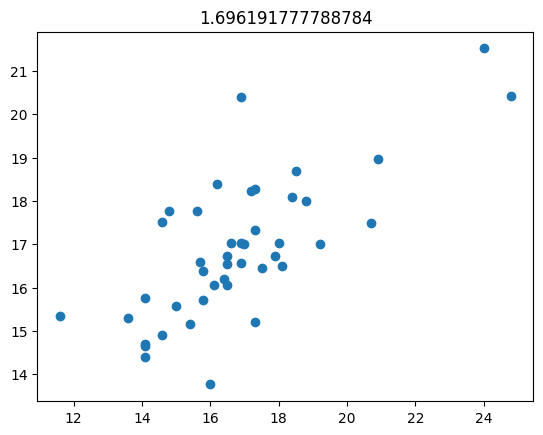

In [ ]:
# Try fused lasso with different regularizations
coefs = {} 
scores = {}
alpha_arr = [0.1,0.3,0.5,0.7,0.9,1.5,4.,10.,]
for alpha in alpha_arr: 
    fl = FusedLasso(alpha=alpha, solver_path=['SCS'])
    # fl = FusedLasso(alpha=alpha)

    try: 
        fl.fit(ss_f.nir_pointwise_features_train, ss_f.br_train)
        ypred = fl.predict(ss_f.nir_pointwise_features_test)
        coefs[alpha] = fl.coef_
        scores[alpha] = root_mean_squared_error(ss_f.br_test, ypred)
        plt.figure()
        plt.scatter(ss_f.br_test, ypred)
        plt.title(scores[alpha])
    except RuntimeError as e: 

        print(e, 'alpha=' + str(alpha))

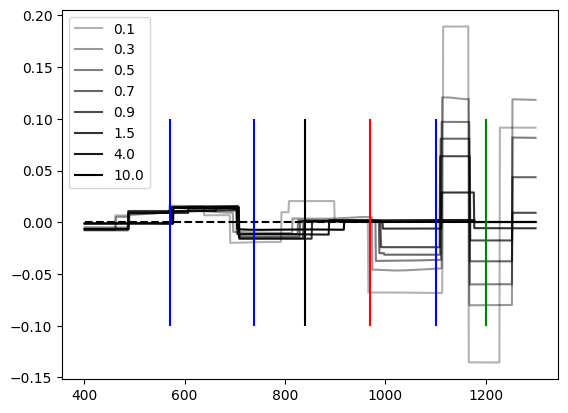

In [ ]:
# f, (ax2) = plt.subplots(1,1,gridspec_kw={'height_ratios': [0.5, 0.7]}, figsize=(7,7), sharex=True, constrained_layout=True)

# for spec in ss_f.nir_pointwise_features: 
#     ax1.plot(ss_f.nir_xaxis, spec, alpha=0.1, color='tab:blue')
f, ax2 = plt.subplots(1,1)
alpha_arr = np.linspace(0.3,1,len(coefs))
for i,alpha in enumerate(coefs):     
    ax2.plot(ss_f.nir_xaxis, coefs[alpha], color='k', alpha=alpha_arr[i], label=alpha)

ax2.legend()
ax2.plot(ss_f.nir_xaxis, np.zeros(len(ss_f.nir_xaxis)), color='k', linestyle='--')

ax2.vlines(970, -0.1, 0.1, color='r', label='970nm')
ax2.vlines(1200, -0.1, 0.1, color='g', label='1150nm')
ax2.vlines(840, -0.1, 0.1, color='k', label='840')
ax2.vlines(738, -0.1, 0.1, color='b', label='738')
ax2.vlines(1100, -0.1, 0.1, color='b', label='1100')
ax2.vlines(570, -0.1, 0.1, color='b', label='550')

In [ ]:
0.86/np.max(ss_f.br) * 100

3.467741935483871

### Sparsest LCEN Model vs. Fused Lasso

Identify the Fused Lasso regularisation strength that gives minimum test RMSE
and compare its sparsity with the LCEN pointwise model (26 selected features).

In [ ]:

scores_arr = [scores[key] for key in scores]
min_idx = np.argmin(scores_arr)
min_alpha = alpha_arr[min_idx]
min_score = scores_arr[min_idx]
fl_score = (min_score) / np.max(br) * 100
fl_score = str(round(fl_score, 2)) + ', min alpha = ' + str(min_alpha)

In [ ]:
for alpha in coefs: 
    coeff_arr = coefs[alpha]
    coeff_arr = np.round(coeff_arr, 3)
    # Create a table of (alpha, coef_value, x_range_start, x_range_end) for contiguous constant segments
    import pandas as pd

    dfs_by_alpha = {}
    for alpha in coefs:
        coeff_arr = coefs[alpha]
        coeff_rounded = np.round(coeff_arr, 3)
        breaks = np.where(np.diff(coeff_rounded)!=0)[0]
        breaks = np.concatenate(([0], breaks+1, [len(coeff_rounded)]))
        alpha_table_data = []
        for i in range(len(breaks)-1):
            start, end = breaks[i], breaks[i+1]
            value = coeff_rounded[start]
            x_start = ss_f.nir_xaxis[start]
            x_end = ss_f.nir_xaxis[end-1]
            alpha_table_data.append({
                "coef_value": value,
                "x_range_start": x_start,
                "x_range_end": x_end
            })
        dfs_by_alpha[alpha] = pd.DataFrame(alpha_table_data)
    # To print each DataFrame for each alpha:
    # for alpha, df_alpha in dfs_by_alpha.items():
    #     print(f"Alpha: {alpha}")
    #     print(df_alpha)
    #     print()

for alpha, df_alpha in dfs_by_alpha.items():
    print(f"Alpha: {alpha}")
    print(df_alpha.to_latex(index=False))
    print()

Alpha: 0.1
\begin{tabular}{rrr}
\toprule
coef_value & x_range_start & x_range_end \\
\midrule
-0.007000 & 401 & 461 \\
0.007000 & 462 & 509 \\
0.008000 & 510 & 531 \\
0.009000 & 532 & 569 \\
0.016000 & 570 & 638 \\
0.007000 & 639 & 690 \\
-0.020000 & 691 & 719 \\
-0.019000 & 720 & 792 \\
0.010000 & 793 & 807 \\
0.020000 & 808 & 848 \\
0.021000 & 849 & 898 \\
0.002000 & 899 & 965 \\
-0.068000 & 966 & 1113 \\
-0.006000 & 1114 & 1114 \\
0.189000 & 1115 & 1165 \\
-0.135000 & 1166 & 1214 \\
-0.136000 & 1215 & 1227 \\
0.091000 & 1228 & 1299 \\
\bottomrule
\end{tabular}


Alpha: 0.3
\begin{tabular}{rrr}
\toprule
coef_value & x_range_start & x_range_end \\
\midrule
-0.007000 & 401 & 463 \\
0.005000 & 464 & 487 \\
0.008000 & 488 & 536 \\
0.009000 & 537 & 564 \\
0.010000 & 565 & 588 \\
0.011000 & 589 & 645 \\
0.010000 & 646 & 679 \\
0.009000 & 680 & 696 \\
-0.009000 & 697 & 716 \\
-0.010000 & 717 & 814 \\
0.004000 & 815 & 860 \\
0.003000 & 861 & 887 \\
0.004000 & 888 & 930 \\
0.005000 & 931 & 97

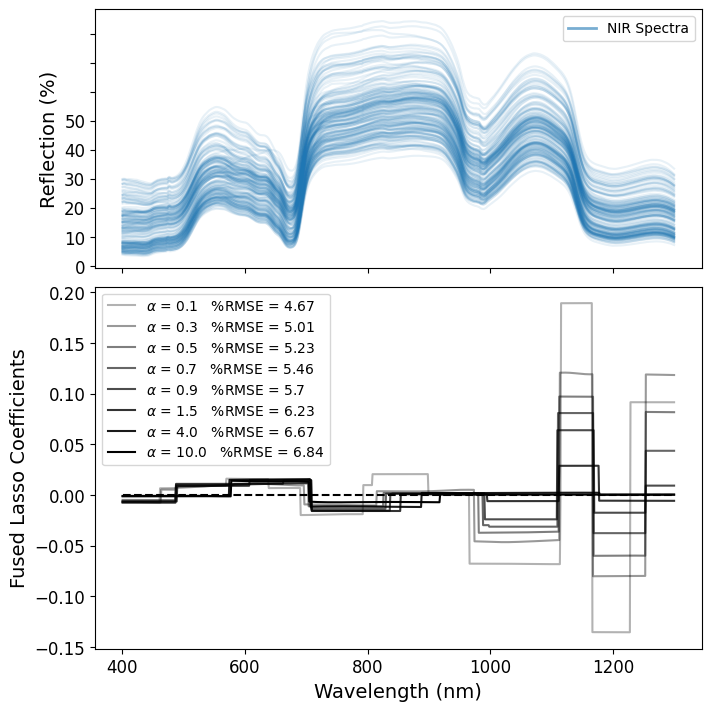

In [ ]:
fontsize=14
for feat in ['nir_pointwise_features']:
        f, (ax1, ax2) = plt.subplots(2,1,gridspec_kw={'height_ratios': [0.5, 0.7]}, figsize=(7,7), sharex=True, constrained_layout=True)
        # f.suptitle('NIR')
        # ax2.bar(ss_f.nir_xaxis, ss_f.nir_pointwise_features_br_FusedLasso['P'].coef_, alpha=0.1, color='k')
        # for spec in ss_f.nir_pointwise_features:
        for spec in XSF_br: 
            spec = spec[selected_wls] 
            ax1.plot(ss_f.nir_xaxis, spec, alpha=0.1, color='tab:blue')
        alpha_arr = np.linspace(0.3,1,len(coefs))
        for i,alpha in enumerate(coefs):     
            ax2.plot(ss_f.nir_xaxis, coefs[alpha], color='k', alpha=alpha_arr[i], label=fr'$\alpha$ = {alpha}' + f'   %RMSE = {round(scores[alpha]/np.max(ss_f.br) * 100, 2)}')
        ax2.plot(ss_f.nir_xaxis, np.zeros(len(ss_f.nir_xaxis)), color='k', linestyle='--')
        ax1.set_ylabel('Reflection (%)', fontsize=fontsize)
        ax2.set_xlabel('Wavelength (nm)', fontsize=fontsize)
        ax2.set_ylabel('Fused Lasso Coefficients', fontsize=fontsize)

# plot_spectral_features_matplotlib(ss_f.nir_xaxis, ss_f.nir_pointwise_features[0], ss_f.nir_polynomial_featuresall_br_LCEN['selected_features'][:10], ax=ax1,zoom=0.04, plot_raw=False)
selected_features = ss_f.nir_pointwise_features_br_LCEN['selected_features']

selected_features = [int(x.replace('x', '')) for x in  np.array(ss_f.nir_pointwise_features_br_LCEN['model_params'])[1:,0]]
selected_vals = [float(x) for x in  np.array(ss_f.nir_pointwise_features_br_LCEN['model_params'])[1:,1]]

# ax1_twin = ax2.twinx()
# sorted = np.argsort(np.abs(selected_vals))[::-1]
# selected_features = np.array(selected_features)[sorted] # sort by the absolute value of the coefs 
# selected_vals = np.array(selected_vals)[sorted]
# for i, index in enumerate(selected_features[:20]):
#     ax1_twin.plot(ss_f.nir_xaxis[index], selected_vals[i], color='#00ADF2', alpha=1, markersize=12,marker='*', markeredgecolor='k')
# ax1_twin.set_ylabel('LCEN Coefficients', fontsize=fontsize, color='#00ADF2')
# Add legend, stars are the features from the polynomial model

from matplotlib.lines import Line2D

# Custom legend elements
lcen_score = (ss_f.nir_pointwise_features_br_LCEN['score']) / np.max(ss_f.br) * 100
legend_elements = [
    Line2D([0], [0], color='tab:blue', lw=2, alpha=0.6, label='NIR Spectra'),
    # Line2D([0], [0], color='k', lw=2, label=f'Fused Lasso, % RMSE = {fl_score}'),
    # Line2D([0], [0], marker='*', markeredgecolor='k', color='w', markerfacecolor='#00ADF2', markersize=12, label=f'LCEN Coefficients, % RMSE = {round(lcen_score,2)}')
]

ax1.legend(handles=legend_elements, loc='upper right', frameon=True)
ax2.legend()
ticksize=12
for ax in [ax1, ax2]:
    ax.set_yticklabels(ax.get_yticklabels(), size=ticksize)
# ax1_twin.set_yticklabels(ax1_twin.get_yticklabels(), size=ticksize, color='#00ADF2')
# ax1_twin.tick_params(axis='y', colors='#00ADF2')
# ax1_twin.spines['right'].set_color('#00ADF2')

ax2.set_xticklabels(ax2.get_xticklabels(), size=ticksize);
plt.subplots_adjust(hspace=0, wspace=0)

from matplotlib.patches import FancyArrowPatch

# arrow = FancyArrowPatch((1950, -0.037), (2150, -0.037),
#                         arrowstyle='->',  # Defines arrow style (e.g., simple, curved)
#                         color='#00ADF2',
#                         mutation_scale=20) # Controls head size
# ax2.add_patch(arrow)

# arrow = FancyArrowPatch((600, 0.03), (450, 0.03),
#                         arrowstyle='->',  # Defines arrow style (e.g., simple, curved)
#                         color='k',
#                         mutation_scale=20) # Controls head size
# ax2.add_patch(arrow)

plt.savefig(f"Figures/Fig5_022526.svg")
plt.savefig(f"Figures/Fig5_022526.pdf")



## LCEN Hyperparameter Sensitivity Analysis

Evaluate how model performance changes when the clip cutoff, alpha (regularisation
strength), and L1 ratio are varied independently, with the other two fixed at
their CV-optimal values.

### Vary Cutoff

Sweep the LCEN clip cutoff threshold from 1 down to 5×10⁻⁵.

In [ ]:
nalpha = 5

bestalpha = 0.00707945784384138
cutoff_used = 5e-5
alpharange = np.round(np.concatenate(([0], np.logspace(-4.3, 0, nalpha))), 7)
cutoff_arr = [1,5e-1,3e-1, 1e-1, 7e-2, 5e-2,3e-2, 1e-2, 5e-3,5e-4,5e-5]
results = []
for cutoff in cutoff_arr: 
    lcen_elbow_kwargs = {'l1_ratio':[0.01],
               'cv_method':None, 
               'degree': [1],
               'alpha': [bestalpha],
               'LCEN_cutoff': cutoff,
               'lag':[0],
               'trans_type': 'poly',
               'LCEN_interaction':False, 
               'scale_X':True, # Make sure False if input data is scaled and centered
               'scale_y':True, #changed from True 
               'metric':root_mean_squared_error}
    
    ss_f.do_LCEN('nir_polynomial_featuresall', 'br', 0.25, **lcen_elbow_kwargs)
    prmse = ss_f.nir_polynomial_featuresall_br_LCEN['score'] / np.max(ss_f.br) * 100
    results.append(prmse)

CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 2.4375 | Mean relative error = 0.1114
Test set : RMSE = 2.4709 | Mean relative error = 0.1054
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 1.8892 | Mean relative error = 0.0889
Test set : RMSE = 2.3161 | Mean relative error = 0.1063
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperpar

### Vary Alpha

Sweep the regularisation strength α from 0 to 1 on a log scale.

In [ ]:
alpharange = np.round(np.concatenate(([0], np.logspace(-4.3, 0, nalpha))), 7)
alpharesults = []
for alph in alpharange: 
    lcen_elbow_kwargs = {'l1_ratio':[0.01],
               'cv_method':None, 
               'degree': [1],
               'alpha': [alph],
               'LCEN_cutoff': cutoff_used,
               'lag':[0],
               'trans_type': 'poly',
               'LCEN_interaction':False, 
               'scale_X':True, # Make sure False if input data is scaled and centered
               'scale_y':True, #changed from True 
               'metric':root_mean_squared_error}
    
    ss_f.do_LCEN('nir_polynomial_featuresall', 'br', 0.25, **lcen_elbow_kwargs)
    prmse = ss_f.nir_polynomial_featuresall_br_LCEN['score'] / np.max(ss_f.br) * 100
    alpharesults.append(prmse)

CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.4773 | Mean relative error = 0.0235
Test set : RMSE = 1.5296 | Mean relative error = 0.0738
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.4833 | Mean relative error = 0.0238
Test set : RMSE = 1.4717 | Mean relative error = 0.0709
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperpar

### Vary L1 Ratio

Sweep the ElasticNet L1 ratio from 0.001 (ridge-like) to 1 (lasso-like).

In [ ]:

bestalpha = 0.00707945784384138
cutoff_used = 5e-5
l1_arr = [0.001, 0.01, 0.1,0.3, 0.5, 0.75,1]
lratio_results = []
for l1 in l1_arr: 
    lcen_elbow_kwargs = {'l1_ratio':[l1],
               'cv_method':None, 
               'degree': [1],
               'alpha': [bestalpha],
               'LCEN_cutoff': cutoff_used,
               'lag':[0],
               'trans_type': 'poly',
               'LCEN_interaction':False, 
               'scale_X':True, # Make sure False if input data is scaled and centered
               'scale_y':True, #changed from True 
               'metric':root_mean_squared_error}
    
    ss_f.do_LCEN('nir_polynomial_featuresall', 'br', 0.25, **lcen_elbow_kwargs)
    prmse = ss_f.nir_polynomial_featuresall_br_LCEN['score'] / np.max(ss_f.br) * 100
    lratio_results.append(prmse)

CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.7341 | Mean relative error = 0.0363
Test set : RMSE = 1.2559 | Mean relative error = 0.0605
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.7343 | Mean relative error = 0.0363
Test set : RMSE = 1.2552 | Mean relative error = 0.0605
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperpar

### Sensitivity Analysis — Results

Plot % RMSE vs. each hyperparameter to identify stable operating regions.

Text(0.5, 1.0, 'Cutoff = 5e-5, $\\alpha$ = 0.007')

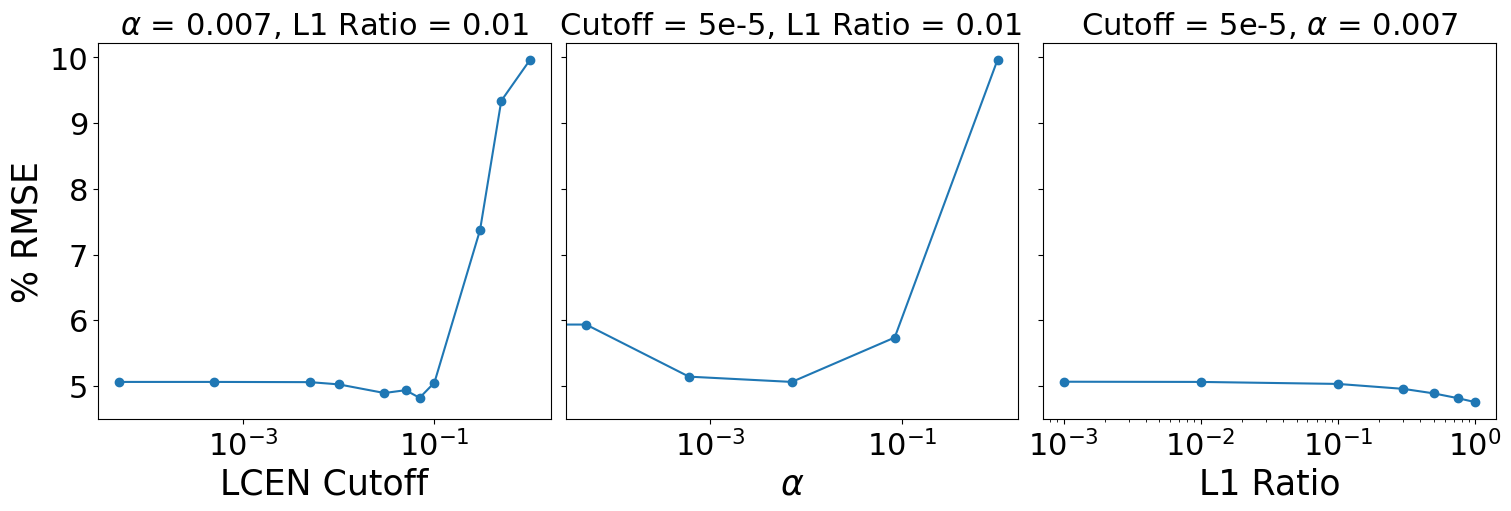

In [ ]:
f, (ax1, ax2, ax3) = plt.subplots(1,3,figsize=(15,5), constrained_layout=True,sharey=True)
ax1.plot(cutoff_arr, results, marker='o')
ax1.set_xlabel('LCEN Cutoff')
ax1.set_ylabel('% RMSE')
ax1.set_xscale('log')

ax2.plot(alpharange, alpharesults, marker='o')
ax2.set_xlabel(r'$\alpha$')
ax2.set_xscale('log')

ax3.plot(l1_arr, lratio_results, marker='o')
ax3.set_xlabel(r'L1 Ratio')
ax3.set_xscale('log')

for ax in [ax1, ax2, ax3]:
    ax.tick_params(axis='both', labelsize=22)
    ax.xaxis.label.set_size(25)
    ax.yaxis.label.set_size(25)
    
ax1.set_title(r'$\alpha$ = 0.007, L1 Ratio = 0.01', fontsize=22)
ax2.set_title(r'Cutoff = 5e-5, L1 Ratio = 0.01', fontsize=22)
ax3.set_title(r'Cutoff = 5e-5, $\alpha$ = 0.007', fontsize=22)

